# Supplementary analysis: the protocol's pupil outcome

The published study protocol (Heinrichs & Spitschan, 2025, *PLOS ONE*,
https://doi.org/10.1371/journal.pone.0300405) named one primary pupil
outcome: the maximum pupil constriction in each stimulus condition, divided by the
maximum constriction to broadband flux in the same block. The manuscript analysed two
different outcomes instead, taken from the main pipeline: the **phasic amplitude**
(how strongly the pupil follows the 0.4 Hz oscillation) and the **tonic minimum** (how
deep the slow, sustained constriction goes).

This notebook computes the protocol's outcome and runs it through the same circadian
models as the main pipeline, so the two can be compared directly.

**Result.** Like the main outcomes, the protocol outcome favours the constant-level
model (no circadian rhythm) in every condition. L-M is the exception only in being
inconclusive, and its result depends on single participants.

**How to read this notebook.** Each step starts from what the main pipeline
(`pipeline.py`, `pipeline.ipynb`) does at the same step number, then says what is
different here and why. Protocol passages are cited by the section of the protocol
paper they appear in.

---

## The protocol outcome

The protocol defines it in its section "Non-image forming visual function"
(Heinrichs & Spitschan, 2025, *PLOS ONE*, https://doi.org/10.1371/journal.pone.0300405):

> "we will obtain a maximum pupil constriction amplitude per trial from the pupil trace.
> Maximum pupil constriction is defined by the maximum difference between pupil diameter
> one second prior to stimulus onset and the pupil diameter during the 5-second stimulus
> presentation. We will calculate the average pupil response amplitude across trials and
> test repetitions for each condition."

The average is then divided by the flux average. Written per participant $i$, block $b$
and condition $c$:

$$R_{ibc} = \frac{\bar{A}_{ibc}}{\bar{A}_{ib,\mathrm{FLUX}}}$$

In three steps:

1. **Per trial:** baseline = mean pupil size in the 1 s before stimulus onset;
   amplitude = baseline minus the smallest pupil size during the 5 s stimulus.
   Constriction is positive.
2. **Per block:** average the trial amplitudes of one participant, block and condition
   (both test repetitions pooled).
3. **Ratio:** divide by the flux average from the *same* participant and block.

Why the same block: the protocol says the comparison with flux is meant to "determine
the unique circadian variation of the photoreceptor mechanisms" (section "Silent substitution stimuli"). Only
a flux value measured at the same time point removes the variation a condition shares
with flux at that time.


## Main pipeline vs this notebook

Step numbers match `pipeline.py`, so the same number means the same stage.
`si_pipeline.py` runs the same steps as this notebook.

| Step | Main pipeline | Supplementary pipeline | Why |
|---|---|---|---|
| 0 | Extract participant demographics | Not run | Demographics do not depend on the outcome |
| 1 | Average all trials and both test repetitions into one trace per participant, condition and block (`data/aggregated/data.csv`) | Not run | The protocol needs each trial before averaging, so Step 3 reads the per-participant files directly |
| 2 | Descriptive pupil metrics | Not run | No later step needs them; Step 3 writes its own summary and exclusion log |
| 3 | Split the averaged trace into tonic (low-pass filter) and phasic (cosinor at 0.4 Hz) parts -> `amplitude`, `tonic_min` | Maximum constriction per trial -> block mean -> ratio to flux in the same block -> `plr_ratio`. Same input files, eye selection, `"pre-stim"` baseline and six-block rule (applied after pairing) | The protocol's outcome (section "Non-image forming visual function") |
| 3b | Plot the cosinor fits | Plot the protocol outcome (Figures 1-3) | Different outcome |
| 3c | Diagnose the pupil cosinor fits | Not run | No per-block cosinor is fitted here |
| 4 | Saliva cosinor: two harmonics, tau searched over 22-28 h | Not run; reads the main tau | Same periods, so only the outcome changes. The protocol had one harmonic and 20-28 h (section "Estimation of circadian period") |
| 4b-5c | Inspect, fit M0/M1, diagnose and plot, per `parameter` | Same functions, per `outcome` (`plr_ratio`, `log_plr_ratio`); four conditions, because flux is the denominator | Same model structure as the protocol (section "Confirmatory analysis"); the log ratio was specified before fitting |
| 6 | -- | Sensitivity analyses: 20-28 h period range; leave-one-participant-out for L-M | Specified before fitting |

**Where outputs go.**

- Steps 4b-5c write into the main result folders under the outcome name, as `amplitude`
  does (for example `results/tables/circadian_cosinor/plr_ratio/`). The names
  `plr_ratio` and `log_plr_ratio` cannot overwrite a main result.
- Steps 3, 3b and 6 have no main counterpart and write to `plr_ratio/` folders under
  `data/derivatives/` and `results/`.

### What this supplementary analysis cannot deliver

Restoring the protocol's *outcome* does not restore the protocol's *analysis*:

- The sequential stopping rule (stop at BF > 10 or < 1/10 for melanopsin,
  section "Sample size") cannot be applied after the fact.
- The priors used here come from the main pipeline; the protocol did not specify any.
- The protocol's period model had one harmonic; the main pipeline's has two. Only the
  period *range* is restored (Step 6), because the single harmonic would mean changing
  the main saliva module.
- These analyses were run **after** the main results were known.

So this is an analysis of the protocol's outcome, not a confirmatory test.


## Config

`FIT = False` runs no sampling: Step 5 only builds the models, and the later steps read
the fits and sensitivity tables already saved on disk. `FIT = True` runs Step 5 and the
Step 6 refits, but Step 5 still loads saved fits where they exist and samples only the
conditions that have none. To resample Step 5 from scratch, set `FORCE = True` as well.
Keep `SMC_DRAWS` at 10000: fewer particles bias the evidence towards the
constant-level model.


In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display, Markdown

pd.set_option('display.width', 200)

FIT       = False   # True -> run SMC sampling (~20 s per condition)
FORCE     = False   # True -> re-run SMC even when saved InferenceData exists
SMC_DRAWS = 10000 
SEED      = 1072

PROJECT = Path.cwd()
# Steps 4b-5c use the primary layout, keyed by outcome name like `amplitude`.
TABLES = PROJECT / 'results' / 'tables' / 'circadian_cosinor'
DIAG   = PROJECT / 'results' / 'tables' / 'circadian_cosinor_diagnostics'
SENS   = PROJECT / 'results' / 'tables' / 'plr_ratio' / 'sensitivity'


## Steps 0, 1, 2 -- not run here

Demographics (Step 0), trial averaging (Step 1) and descriptive metrics (Step 2) are
not needed for the protocol outcome; see the overview table for why. Step 3 reads the
per-participant files itself.

## Step 3 -- Derive the protocol outcome (replaces main Steps 1-3)

**Main pipeline.** Step 1 averages all trials of a block into one trace and saves it
as `data/aggregated/data.csv`; Step 3 fits the cosinor to that trace.

**Supplementary pipeline.** `data/aggregated/data.csv` cannot be used, because by then
the trials are already averaged, and the protocol needs the maximum of each trial
*before* averaging. This step therefore reads the same per-participant files as main
Step 1, with the same eye selection and the same `"pre-stim"` baseline, and then:

1. takes one amplitude per trial,
2. averages them per participant, condition and block,
3. divides by flux from the same block,
4. applies the main pipeline's six-block rule.

**In:** `data/retinawise_results/final/<ID>_final_data.csv`
**Out:** `data/derivatives/plr_ratio/` (`trial_amplitudes.csv`, `block_amplitudes.csv`,
`paired_ratios_all.csv`, `paired_ratios_analysis.csv`, `exclusion_log.csv`,
`derivation_summary.csv`) and `results/tex/plr_ratio/vars_plr_ratio.tex`

**Why the order is checked.** Averaging first and then taking one maximum (the main
pipeline's order) gives amplitudes only 0.06-0.15 mm smaller. Both land near 1 mm, so a
swap would go unnoticed. `audit_ordering()` computes both and stores the difference in
the block table (see 3.3).


In [2]:
from civibeplr.si_derive_protocol_plr import derive_plr_ratio_endpoint

out      = derive_plr_ratio_endpoint()
trials   = out['trials']
blocks   = out['blocks']
analysis = out['analysis']

display(out['exclusions'])



Deriving protocol PLR endpoint from 12 participant files...
  Trials: 3562 (3562 valid)
  Blocks: 453 (453 valid)

Pairing each condition with its matched FLUX block...
  Paired: 358 of 358 non-FLUX blocks

Applying the 6-block rule after pairing...
  Excluding 15 participant-condition pairs with < 6 blocks:
    participant 205, condition 'l-m': 3 block(s)
    participant 207, condition 'l-m': 4 block(s)
    participant 209, condition 'l-m': 1 block(s)
    participant 210, condition 'l-m': 3 block(s)
    participant 213, condition 'l-m': 4 block(s)
    participant 205, condition 'lms': 4 block(s)
    participant 207, condition 'lms': 4 block(s)
    participant 209, condition 'lms': 1 block(s)
    participant 210, condition 'lms': 3 block(s)
    participant 205, condition 'mel': 3 block(s)
    participant 207, condition 'mel': 3 block(s)
    participant 210, condition 'mel': 3 block(s)
    participant 205, condition 's': 1 block(s)
    participant 207, condition 's': 4 block(s)
    part

,condition,n_trials_total,n_trials_valid,n_blocks_total,n_blocks_valid,n_blocks_paired,n_blocks_no_flux,n_blocks_analysis,n_participants_analysis
0,flux,732,732,95,95,0,0,0,0
1,l-m,702,702,89,89,89,0,74,7
2,lms,734,734,92,92,92,0,80,8
3,mel,690,690,89,89,89,0,80,8
4,s,704,704,88,88,88,0,81,8


#### Conclusion: pairing loses nothing, the six-block rule does the excluding

- Every block that has a condition also has flux (flux is present in all 95
  participant-blocks), so no block is lost to pairing.
- The six-block rule drops 15 participant-condition series, all from participants 205,
  207, 209, 210 and 213.
- That leaves 74-81 observations per condition from 7 (L-M) or 8 participants, exactly
  the counts behind the main pipeline's phasic amplitude for these four conditions.

The rule is still applied after pairing, because that is the correct order, even though
it changes nothing here.


### 3.1 -- Edge cases: zero, negative or tiny amplitudes

A ratio breaks if an amplitude is zero or negative, or if the flux denominator is close
to zero. This checks whether any of that happens.


In [3]:
checks = pd.DataFrame({
    'n_block_amplitudes_le_0': [(blocks['mean_constriction_mm'] <= 0).sum()],
    'n_trial_amplitudes_le_0': [(trials['constriction_amplitude_mm'] <= 0).sum()],
    'n_trials_total'         : [len(trials)],
    'min_flux_denominator_mm': [analysis['flux_constriction_mm'].min().round(3)],
    'pct5_flux_denominator'  : [analysis['flux_constriction_mm'].quantile(.05).round(3)],
    'n_ratios_le_0'          : [(analysis['plr_ratio'] <= 0).sum()],
}).T.rename(columns={0: 'value'})
display(checks)


,value
n_block_amplitudes_le_0,0.000
n_trial_amplitudes_le_0,102.000
n_trials_total,3562.000
min_flux_denominator_mm,0.363
pct5_flux_denominator,0.457
n_ratios_le_0,0.000


#### Conclusion: none of them occur

- No block amplitude is at or below zero. 102 of 3562 single trials are, but they
  average out within their blocks.
- The smallest flux denominator in the analysed rows is 0.36 mm, 5th percentile 0.46 mm
  (0.29 and 0.43 mm across all flux blocks, before the six-block rule). Nothing is near
  zero.
- Every ratio is positive, so the log ratio (Steps 4b-5c) exists for every observation.


### 3.2 -- What maximum constriction measures

The main pipeline separates the slow, sustained constriction (tonic) from the
oscillation at the stimulus frequency (phasic). Maximum constriction mixes the two. The
table below sets it next to both main-pipeline outcomes, block by block on the same
blocks, to show which part dominates.

`blocks` still holds the series that the six-block rule removes, and flux is never put
through the rule here because it is only the denominator. The join with the main Step 3
table restricts all three measures to the blocks the main pipeline analyses.

In [4]:
cosinor = pd.read_csv(PROJECT / 'results' / 'tables' / 'pupil_cosinor'
                      / 'pupil_cosinor_2step_param.csv')
keys = ['Participant id', 'Trial type', 'Block']
measures = (blocks[keys + ['mean_constriction_mm']]
            .merge(cosinor[keys + ['tonic_min', 'amplitude']], on=keys,
                   how='inner', validate='1:1')
            .rename(columns={'mean_constriction_mm': 'max_constriction_mm',
                             'amplitude': 'phasic_amplitude_mm'}))
# tonic_min is negative (below baseline); flip it to a depth like the other two.
measures['tonic_depth_mm'] = -measures.pop('tonic_min')
MEASURES = ['max_constriction_mm', 'tonic_depth_mm', 'phasic_amplitude_mm']

cond_means = (measures.groupby('Trial type')[MEASURES].mean().round(2)
              .assign(n_blocks=measures.groupby('Trial type').size())
              .sort_values('max_constriction_mm', ascending=False))
display(cond_means)

,max_constriction_mm,tonic_depth_mm,phasic_amplitude_mm,n_blocks
Trial type,,,,
l-m,1.26,0.92,0.12,74
lms,1.02,0.53,0.22,80
flux,1.01,0.45,0.26,83
s,1.01,0.59,0.19,81
mel,0.81,0.44,0.09,80


In [5]:
# Descriptive Pearson r between the three block-level measures. "raw" mixes
# differences between participants with block-to-block changes; "within" first
# subtracts each participant's mean per condition, so only block-to-block changes remain.
PAIRS = [('max_constriction_mm', 'tonic_depth_mm'),
         ('max_constriction_mm', 'phasic_amplitude_mm'),
         ('tonic_depth_mm', 'phasic_amplitude_mm')]

def pair_corrs(df):
    groups = [('all', df)] + list(df.groupby('Trial type'))
    return pd.DataFrame({
        g: {f"{a.split('_')[0]} ~ {b.split('_')[0]}": d[a].corr(d[b]) for a, b in PAIRS}
        for g, d in groups}).T

within = measures.copy()
within[MEASURES] -= within.groupby(['Participant id', 'Trial type'])[MEASURES].transform('mean')

measure_corrs = pd.concat({'raw': pair_corrs(measures), 'within': pair_corrs(within)},
                          axis=1).round(2)
display(measure_corrs)

raw                                  within                            
     max ~ tonic max ~ phasic tonic ~ phasic max ~ tonic max ~ phasic tonic ~ phasic
all         0.92         0.51           0.32        0.87         0.49           0.36
flux        0.89         0.80           0.83        0.76         0.61           0.52
l-m         0.95         0.05           0.05        0.94         0.41           0.38
lms         0.94         0.83           0.77        0.79         0.53           0.22
mel         0.95         0.41           0.35        0.92         0.34           0.30
s           0.93         0.76           0.68        0.93         0.51           0.46

#### Conclusion: maximum constriction mostly reflects the sustained constriction

**Ranking.** Maximum constriction ranks the conditions like the tonic minimum, not like
the phasic amplitude: L-M comes first and Mel last on both. S, LMS and flux are within
0.01 mm of each other, so their order carries no information. L-M moves from fourth
place on the phasic amplitude to first place here, and flux, the strongest oscillation,
sits in the middle.

**Correlations (descriptive).** Maximum constriction tracks the tonic minimum closely in
every condition (r = 0.89-0.95 raw, 0.76-0.94 within participants). Its link to the
phasic amplitude is weaker and varies across conditions; in L-M it is absent in the raw
data (r = 0.05).

**Why.** Figure 1A shows each trial as a large sustained constriction away from the
white background between trials, with the 0.4 Hz oscillation riding on top. The deepest
point in 0-5 s is set mostly by the sustained constriction, and L-M constricts deepest
and recovers most slowly. The oscillation still leaves a mark: the minima cluster near
the troughs of the pupil response at about 1.75 s and 4.25 s (Figure 1B), closely for
flux, LMS and S but hardly at all for L-M, so maximum constriction is not a measure of how well the pupil follows the oscillation.

This does not make the protocol outcome invalid. It is a legitimate pupil measure, but
it measures something other than the phasic and tonic outcomes, which is the main
reason the manuscript separates the two.

### 3.3 -- Order of operations: per trial or averaged trace

The main pipeline averages first and takes one extreme value from the averaged trace.
The protocol takes the maximum per trial and averages afterwards. Both are computed
below on the same data.


In [6]:
ordering = (blocks.groupby('Trial type')[
    ['mean_constriction_mm', 'mean_constriction_avgtrace_mm', 'ordering_bias_mm']]
    .mean().round(3))
ordering['bias_pct_of_endpoint'] = (100 * ordering['ordering_bias_mm']
                                    / ordering['mean_constriction_mm']).round(1)
display(ordering)


,mean_constriction_mm,mean_constriction_avgtrace_mm,ordering_bias_mm,bias_pct_of_endpoint
Trial type,,,,
flux,0.996,0.867,0.128,12.9
l-m,1.239,1.179,0.060,4.8
lms,0.995,0.872,0.123,12.4
mel,0.806,0.660,0.146,18.1
s,0.999,0.928,0.070,7.0


In [7]:
# Within-participant SD of R under each ordering: the noise floor the circadian sine/cosine terms have to clear.
piv_pt = blocks.pivot_table(index=['Participant id','Block'],
                            columns='Trial type', values='mean_constriction_mm')
piv_av = blocks.pivot_table(index=['Participant id','Block'],
                            columns='Trial type', values='mean_constriction_avgtrace_mm')
rows = []
for c in ['l-m','lms','mel','s']:
    r_pt = (piv_pt[c]/piv_pt['flux']).dropna()
    r_av = (piv_av[c]/piv_av['flux']).dropna()
    rows.append({'condition': c,
                 'within_pp_SD_per_trial': r_pt.groupby(level=0).std().mean(),
                 'within_pp_SD_avg_trace': r_av.groupby(level=0).std().mean(),
                 'corr_between_orderings': np.corrcoef(
                     r_pt.align(r_av, join='inner')[0],
                     r_pt.align(r_av, join='inner')[1])[0,1]})
display(pd.DataFrame(rows).round(3))


,condition,within_pp_SD_per_trial,within_pp_SD_avg_trace,corr_between_orderings
0,l-m,0.525,0.710,0.848
1,lms,0.472,0.538,0.917
2,mel,0.379,0.412,0.830
3,s,0.373,0.492,0.844


#### Conclusion: the protocol's order is also the less noisy one here

- **Why the per-trial order is larger.** The deepest sample of a single noisy trial is
  deeper than the deepest sample of a smoothed average, so the per-trial order carries
  an upward bias of 0.06-0.15 mm.
- **Why it is less noisy anyway.** It averages about eight separate maxima per block,
  whereas the averaged trace yields a single extreme value. The within-participant SD
  of R is lower in every condition.
- **What matters for the circadian model.** A roughly constant bias only shifts the
  intercept. The block-to-block spread is what the sine and cosine terms have to rise
  above, so less spread is the better property.

The bias is still reported. It is 5-18% of the amplitude and differs between conditions
(mel +0.146 mm, l-m +0.060 mm), so R carries a small condition-specific bias. The two
orders correlate at r = 0.83-0.92, so this choice could not change a Bayes factor
qualitatively.


## Step 3b -- Visualise the protocol outcome

**Main pipeline.** Step 3b plots the cosinor fits to the averaged traces.

**Supplementary pipeline.** Figures 1-3 show what the protocol outcome measures. The
first cell below prepares the data; each figure is then drawn under its own caption.
Flux is always drawn dashed and labelled directly, because its colour is hard to tell
apart from mel and l-m with some colour-vision deficiencies.

**In:** Step 3 outputs in `data/derivatives/plr_ratio/`
**Out:** `results/figures/plr_ratio/`, `results/tex/plr_ratio/vars_plr_ratio_traces.tex`


In [8]:
from civibeplr.si_visualise_protocol_plr import (
    compute_grand_mean_traces,
    export_trace_variables,
    plot_endpoint_characterisation,
    plot_ordering_audit,
    plot_ratio_distributions,
)

# The same inputs endpoint_figures() uses in the script: the Step 3 outputs on disk.
DERIV = PROJECT / 'data' / 'derivatives' / 'plr_ratio'
fig_blocks   = pd.read_csv(DERIV / 'block_amplitudes.csv')
fig_analysis = pd.read_csv(DERIV / 'paired_ratios_analysis.csv')

traces, min_times = compute_grand_mean_traces()
export_trace_variables(traces, min_times)

PosixPath('/Users/hheinrichs/Documents/projects/civibe_pupillometry/results/tex/plr_ratio/vars_plr_ratio_traces.tex')

### Figure 1 -- what maximum constriction measures

`results/figures/plr_ratio/fig_plr_ratio_endpoint.png`

- **(A)** Grand-mean traces, each trial corrected to its own pre-stimulus baseline, over
  the 0-5 s window in which the maximum is taken. Flux, the denominator, is dashed. L-M
  constricts deepest and recovers most slowly.
- **(B)** When the minimum occurs, one row per condition. The percentage is the share
  of minima within 0.5 s of a pupil-response trough: 85% for flux, 46% for L-M, against
  40% expected by chance (the two windows cover 2 of the 5 s).
- **(C)** Mean block amplitude by condition. L-M comes first, the reverse of its place on
  the phasic amplitude.


Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/plr_ratio/fig_plr_ratio_endpoint.png


PosixPath('/Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/plr_ratio/fig_plr_ratio_endpoint.png')

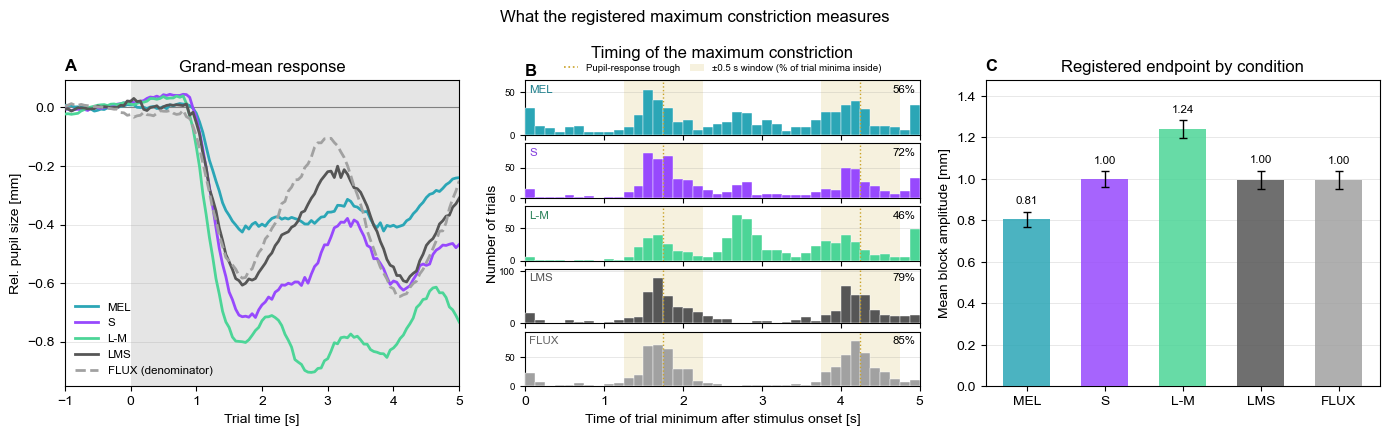

In [9]:
plot_endpoint_characterisation(traces, min_times, fig_blocks)

### Figure 2 -- order of operations

`results/figures/plr_ratio/fig_plr_ratio_ordering.png`

- **(A)** Five condition-specific panels (MEL, S, L-M, LMS, FLUX) compare the
  per-trial and averaged-trace orders. Each point represents one participant and
  block within that condition. All panels use identical limits and equal axis
  scaling; dashed lines mark equality.
- **(B)** Mean difference between the two orders by condition, with standard errors.
  The per-trial order is larger by 5-18% of the amplitude, and by different amounts
  in different conditions.


Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/plr_ratio/fig_plr_ratio_ordering.png


PosixPath('/Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/plr_ratio/fig_plr_ratio_ordering.png')

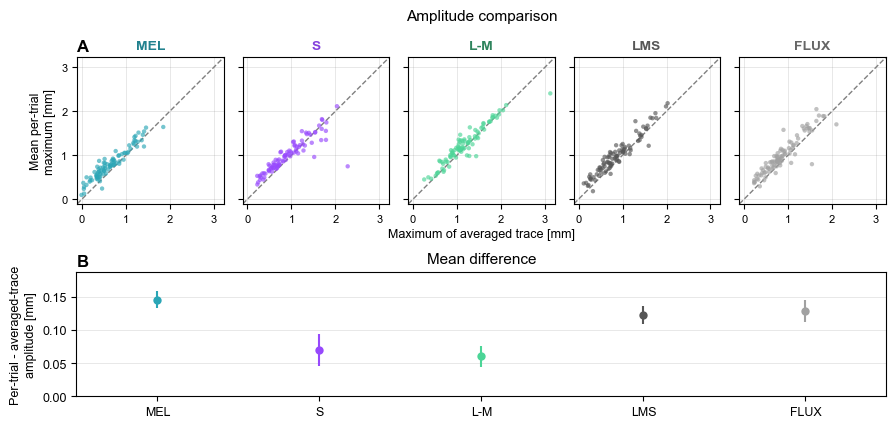

In [10]:
plot_ordering_audit(fig_blocks)

### Figure 3 -- ratio distributions

`results/figures/plr_ratio/fig_plr_ratio_ratios.png`

Half-violins show the distribution across blocks. Small circles show individual
blocks, diamonds participant means, and short horizontal lines condition medians
across blocks. The dashed line is R = 1, a response equal to flux in the same block.
Mel sits below 1 (weaker than flux), L-M above.


Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/plr_ratio/fig_plr_ratio_ratios.png


PosixPath('/Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/plr_ratio/fig_plr_ratio_ratios.png')

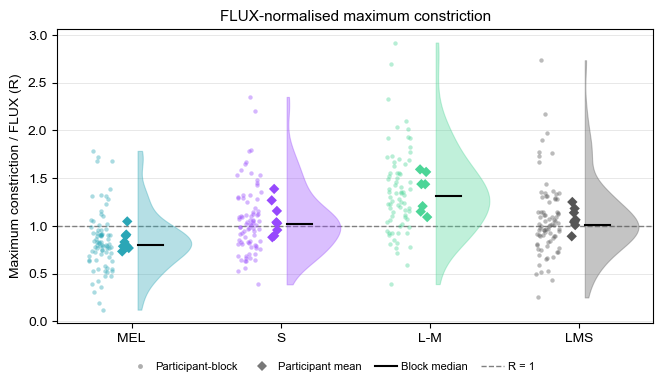

In [11]:
plot_ratio_distributions(fig_analysis)

## Step 3c -- Diagnose pupil cosinor models (not run here)

**Main pipeline.** Residual checks on the per-block cosinor fits.

**Supplementary pipeline.** Not run. No per-block cosinor is fitted, so there is nothing to diagnose.

## Step 4 -- Saliva cosinor (reused from the main pipeline)

**Main pipeline.** Fits a cosinor with **two harmonics** to each participant's salivary
melatonin: the fundamental (period $\tau$) plus the second harmonic (period $\tau/2$),
five parameters in total. It repeats the fit for every candidate $\tau$ from 22 to 28 h
and keeps the $\tau$ with the lowest AIC. Output:
`results/tables/saliva_cosinor/saliva_cosinor_best_fit.csv`.

**Supplementary pipeline.** Not run. Step 5 reads each participant's best $\tau$ from
that file, so main Step 4 must run first. Only $\tau$ is used; the melatonin amplitudes
and phases are not.

**Why reuse it.** With the same $\tau$ as the main analysis, the outcome is the only
thing that differs between the main analysis and this one.

**How this differs from the protocol** (section "Estimation of circadian period"):

| | Protocol | Used here (= main pipeline) | Restored? |
|---|---|---|---|
| Harmonics | One (fundamental only, three parameters) | Two (fundamental + second harmonic, five parameters) | No |
| $\tau$ search range | 20-28 h | 22-28 h | Tested in Step 6a |

The single-harmonic model is not restored, because that would mean changing the main
saliva module. So the periods used here come from the two-harmonic fit, in this
analysis and in the Step 6a refit alike.


## Steps 4b, 5, 5b, 5c -- per outcome

As in `pipeline.ipynb`, these steps repeat for each outcome and call the same functions
as the main pipeline:

- **Step 4b** inspects the distribution of the outcome before modelling.
- **Step 5** fits the M0/M1 pair per condition.
- **Step 5b** runs the model diagnostics.
- **Step 5c** plots the fits.

Two outcomes:

- `plr_ratio`, the protocol outcome;
- `log_plr_ratio`, its logarithm, a sensitivity analysis specified before fitting.


In [12]:
from civibeplr.si_analyse_plr_ratio import (
    inspect as inspect_protocol_plr,
    main as analyse_protocol_plr,
    diagnose as diagnose_protocol_plr,
)
from civibeplr.si_visualise_protocol_plr import circadian_figures

protocol_inspect_results = {}
protocol_results = {}
protocol_diag_results = {}

## Outcome: plr_ratio

The protocol outcome $R_{ibc}$, for the four non-flux conditions.


### Step 4b -- Inspect outcome distribution: plr_ratio

Same as main Step 4b (`inspect_parameter_distribution`): histogram, Q-Q plot,
Shapiro-Wilk test, skewness and kurtosis per condition. Written to
`results/figures/circadian_cosinor/fig_parameter_distribution_plr_ratio.png`.

**Why this matters more here than in the main pipeline.** A ratio inherits skew from its
denominator: a block with small flux constriction produces a large ratio, so a right
tail is expected. Step 5 assumes normally distributed residuals.

**Reading it.** This is the distribution of all observations pooled. The model's
assumption is about the residuals after each participant's own level is removed, so
Step 5b is the actual check. With 74-81 observations, Shapiro-Wilk flags small
departures; look at the Q-Q plot as well.


Loaded 315 paired ratios from paired_ratios_analysis.csv

Analysis dataframe: 315 rows  |  8 participants  |  4 conditions
\Parameter distribution check: 'plr_ratio'
Condition        N     Mean       SD     Skew     Kurt        W        p  Normal?
---------------------------------------------------------------------------------
l-m             74    1.358    0.448    0.903    1.610   0.9554   0.0107  NO
lms             80    1.073    0.394    1.378    3.522   0.9047   0.0000  NO
mel             80    0.845    0.319    0.756    1.248   0.9450   0.0018  NO
s               81    1.066    0.357    1.113    1.813   0.9322   0.0003  NO

  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/fig_parameter_distribution_plr_ratio.png


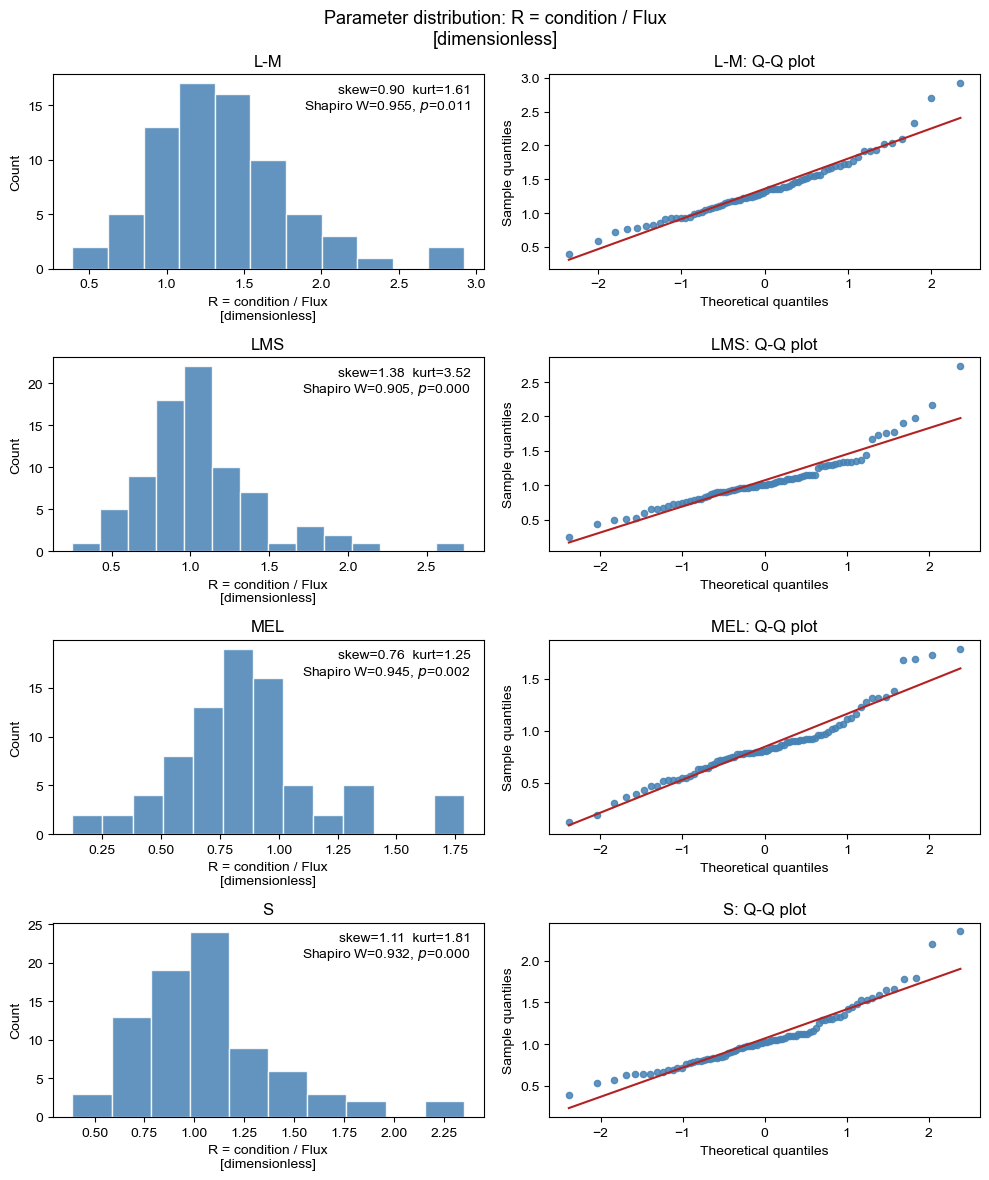

In [13]:
protocol_inspect_results["plr_ratio"] = inspect_protocol_plr(outcome_col="plr_ratio")

#### Conclusion: right-skewed in every condition

All four conditions are right-skewed (skewness 0.76-1.38) and fail Shapiro-Wilk
(p <= 0.011). LMS has the heaviest tail (excess kurtosis 3.5). The same departure shows
up in the Step 5b residuals, so it is not only caused by pooling participants.


### Step 5 -- Circadian models: plr_ratio

Same as main Step 5: the M0/M1 pair per condition, with the same functions, priors and
SMC settings as for `amplitude` and `tonic_min`. Flux is not modelled.

$$M_0:\ R = \mu_c + u_{0ic} + \varepsilon \qquad
M_1:\ R = \mu_c + u_{0ic} + (a_c + u_{aic})\,\alpha + (b_c + u_{bic})\,\beta + \varepsilon$$

M0 has a population intercept and one intercept per participant. M1 adds a sine
($\alpha$) and a cosine ($\beta$) term at each participant's circadian period, with
participant-specific slopes. This is the structure the protocol specified
(section "Confirmatory analysis").

Sampling runs only with `FIT = True` (see Config); otherwise this cell only builds the
models.

**In:** `data/derivatives/plr_ratio/paired_ratios_analysis.csv`, saliva tau from main Step 4
**Out:** `results/tables/circadian_cosinor/plr_ratio/`,
`data/derivatives/circadian_cosinor/plr_ratio/` (saved fits)


In [14]:
df_protocol_plr_ratio, protocol_results["plr_ratio"] = analyse_protocol_plr(
    outcome_col="plr_ratio",
    force=FORCE,
    dry_run=not FIT,
    smc_draws=SMC_DRAWS,
    random_seed=SEED,
)

Loaded 315 paired ratios from paired_ratios_analysis.csv

Analysis dataframe: 315 rows  |  8 participants  |  4 conditions

── Outcome descriptives ──
Trial type  n_obs  n_participants  numerator_mean_mm  denominator_mean_mm  denominator_min_mm  ratio_mean  ratio_sd  ratio_median  ratio_min  ratio_max  ratio_skew  ratio_iqr
       l-m     74               7              1.259                1.000               0.363       1.358     0.448         1.312      0.391      2.921       0.922      0.493
       lms     80               8              1.022                0.995               0.363       1.073     0.394         1.008      0.252      2.736       1.405      0.384
       mel     80               8              0.811                1.005               0.363       0.845     0.319         0.805      0.124      1.787       0.771      0.294
         s     81               8              1.010                1.002               0.363       1.066     0.357         1.018      0.389      2.3

In [15]:
res = pd.read_csv(TABLES / 'plr_ratio' / 'circadian_pupil_all_conditions.csv')
cols = ['condition','n_obs','log_bf10','m1_alpha_estimate','m1_alpha_lo','m1_alpha_hi',
        'm1_beta_estimate','m1_beta_lo','m1_beta_hi']
tbl = res[cols].copy()
tbl['BF01'] = (10 ** -tbl['log_bf10']).round(1)
display(tbl.round(3))


,condition,n_obs,log_bf10,m1_alpha_estimate,m1_alpha_lo,m1_alpha_hi,m1_beta_estimate,m1_beta_lo,m1_beta_hi,BF01
0,l-m,74,-0.321,-0.161,-0.338,0.026,-0.081,-0.228,0.071,2.1
1,lms,80,-2.090,-0.047,-0.201,0.108,0.000,-0.132,0.134,122.9
2,mel,80,-1.383,-0.055,-0.186,0.077,-0.039,-0.145,0.071,24.2
3,s,81,-1.581,-0.110,-0.231,0.015,0.000,-0.114,0.110,38.1


#### Conclusion: the constant-level model is favoured in every condition

- LMS, S and Mel give strong evidence for a constant level (BF01 = 24-123).
- L-M is inconclusive (BF01 = 2.1); Step 6b shows it depends on single participants.
- All sine and cosine credible intervals include zero. The largest slope is L-M's sine
  term, -0.161 [-0.338, 0.026].


### Step 5b -- Diagnose circadian models: plr_ratio

Same as main Step 5b. For this outcome it is essential rather than routine: the ratio
is skewed (Step 4b), so the normal likelihood has to be checked.

**Figures below.** One diagnostics panel per condition (written to
`results/figures/circadian_cosinor_diagnostics/plr_ratio/`): prior and posterior predictive
checks, random-effects shrinkage, residual plots (histogram, Q-Q plot, residuals against
fitted values and against time) and the autocorrelation of residuals within
participants. The last figure shows the spread of log Z across SMC runs for every
condition, which sets how precisely the Bayes factor is known.


Auto-detected conditions: ['l-m', 'lms', 'mel', 's']

── Condition: L-M ──────────────────
  Bayesian p-value: p_B(mean)=0.379  p_B(SD)=0.639
  Saved: posterior_params_l-m.csv
  r_hat  M0 max=1.0021  M1 max=1.0008
  Saved: fig_plr_ratio_diagnostics_l-m.png

── Condition: LMS ──────────────────
  Bayesian p-value: p_B(mean)=0.458  p_B(SD)=0.679
  Saved: posterior_params_lms.csv
  r_hat  M0 max=1.0002  M1 max=1.0003
  Saved: fig_plr_ratio_diagnostics_lms.png

── Condition: MEL ──────────────────
  Bayesian p-value: p_B(mean)=0.463  p_B(SD)=0.667
  Saved: posterior_params_mel.csv
  r_hat  M0 max=1.0003  M1 max=1.0007
  Saved: fig_plr_ratio_diagnostics_mel.png

── Condition: S ──────────────────
  Bayesian p-value: p_B(mean)=0.372  p_B(SD)=0.653
  Saved: posterior_params_s.csv
  r_hat  M0 max=1.0019  M1 max=1.0003
  Saved: fig_plr_ratio_diagnostics_s.png
  Saved: logz_variance_all_conditions.png
Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/tables/circadian_cosino

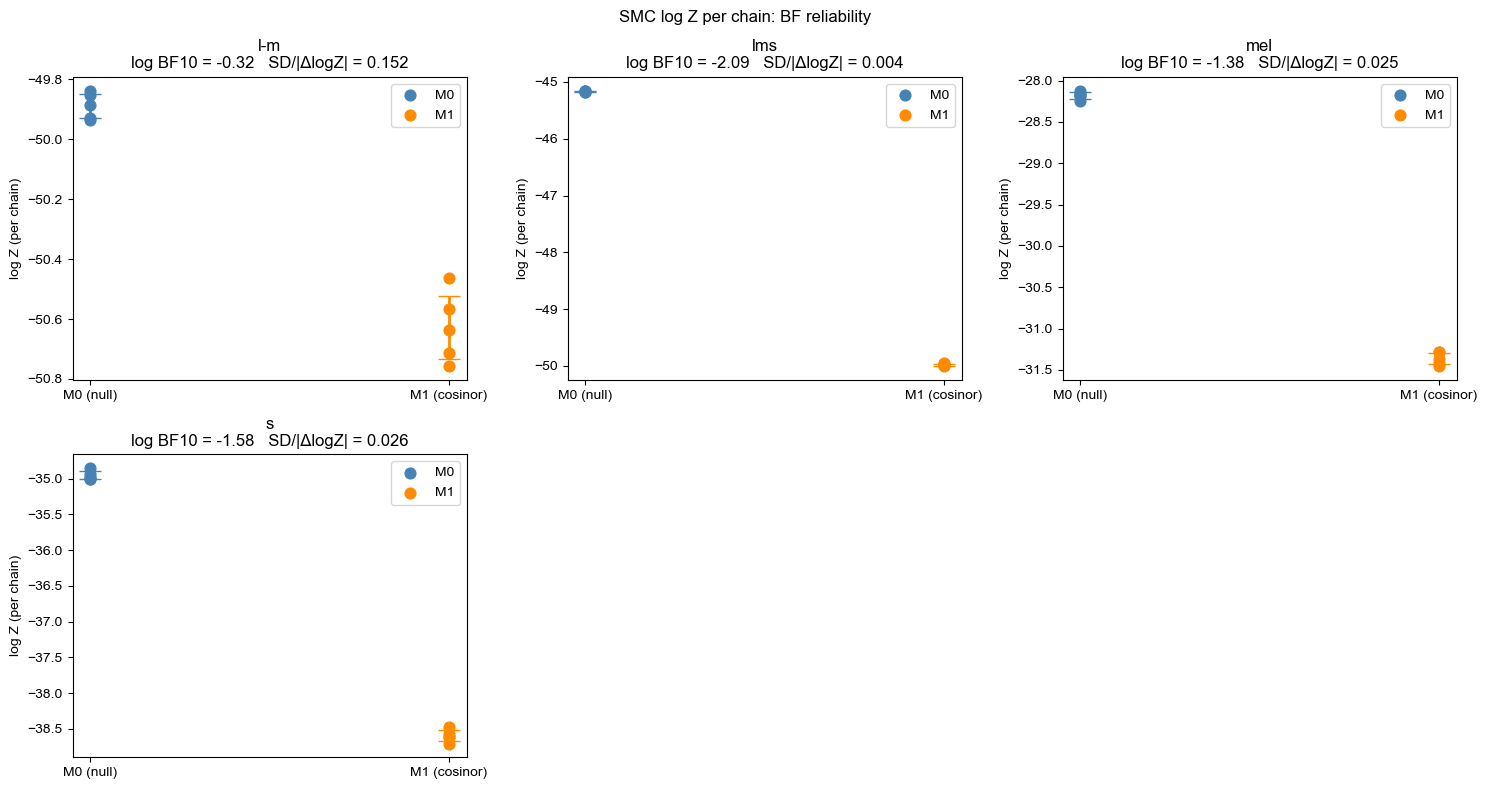

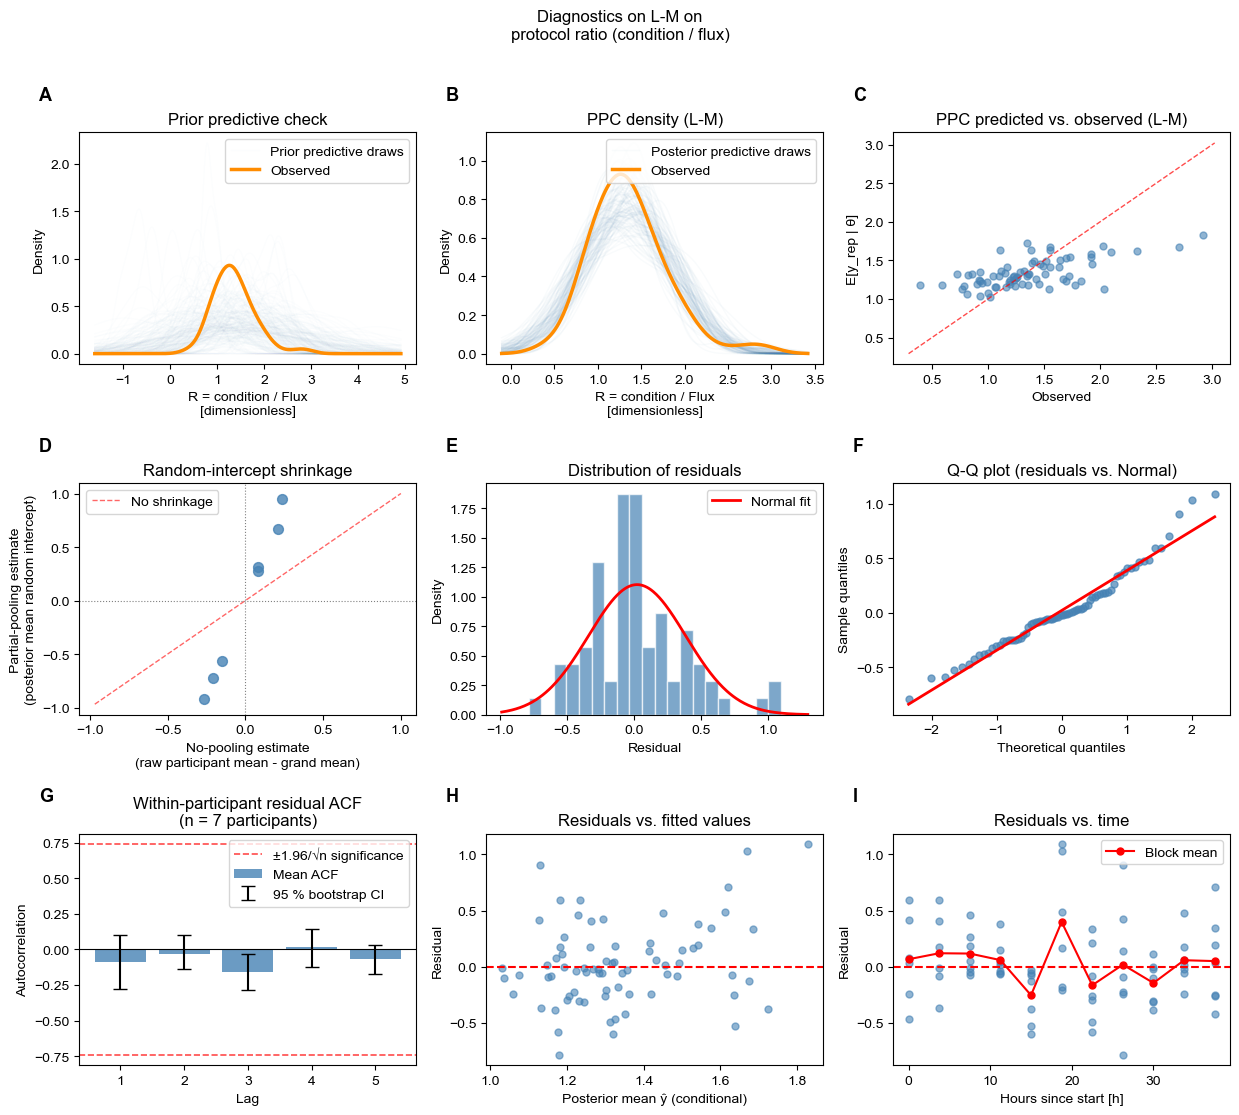

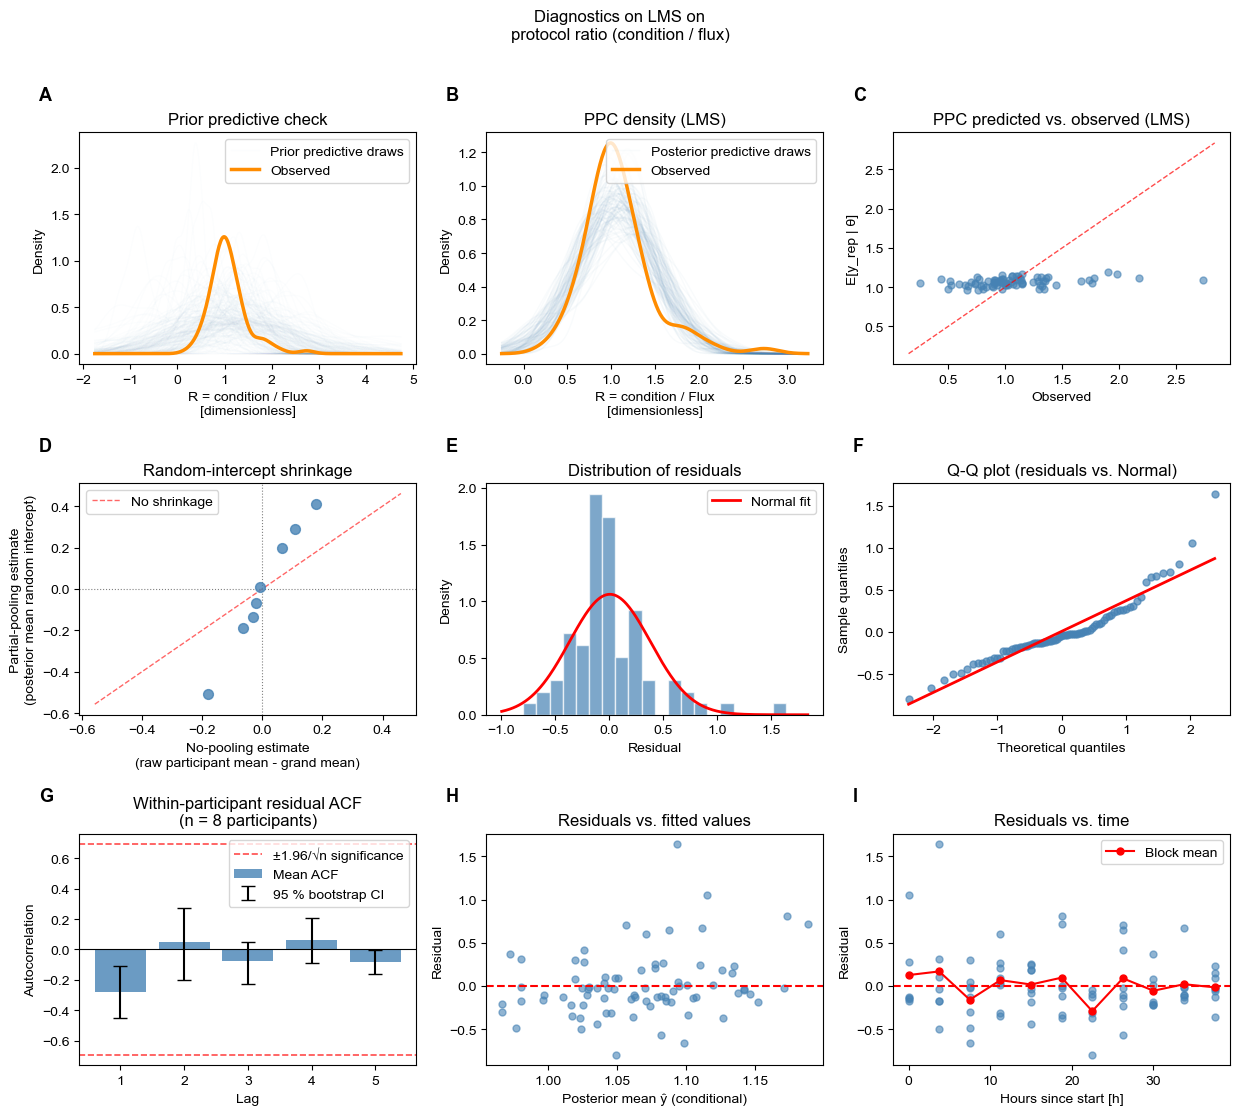

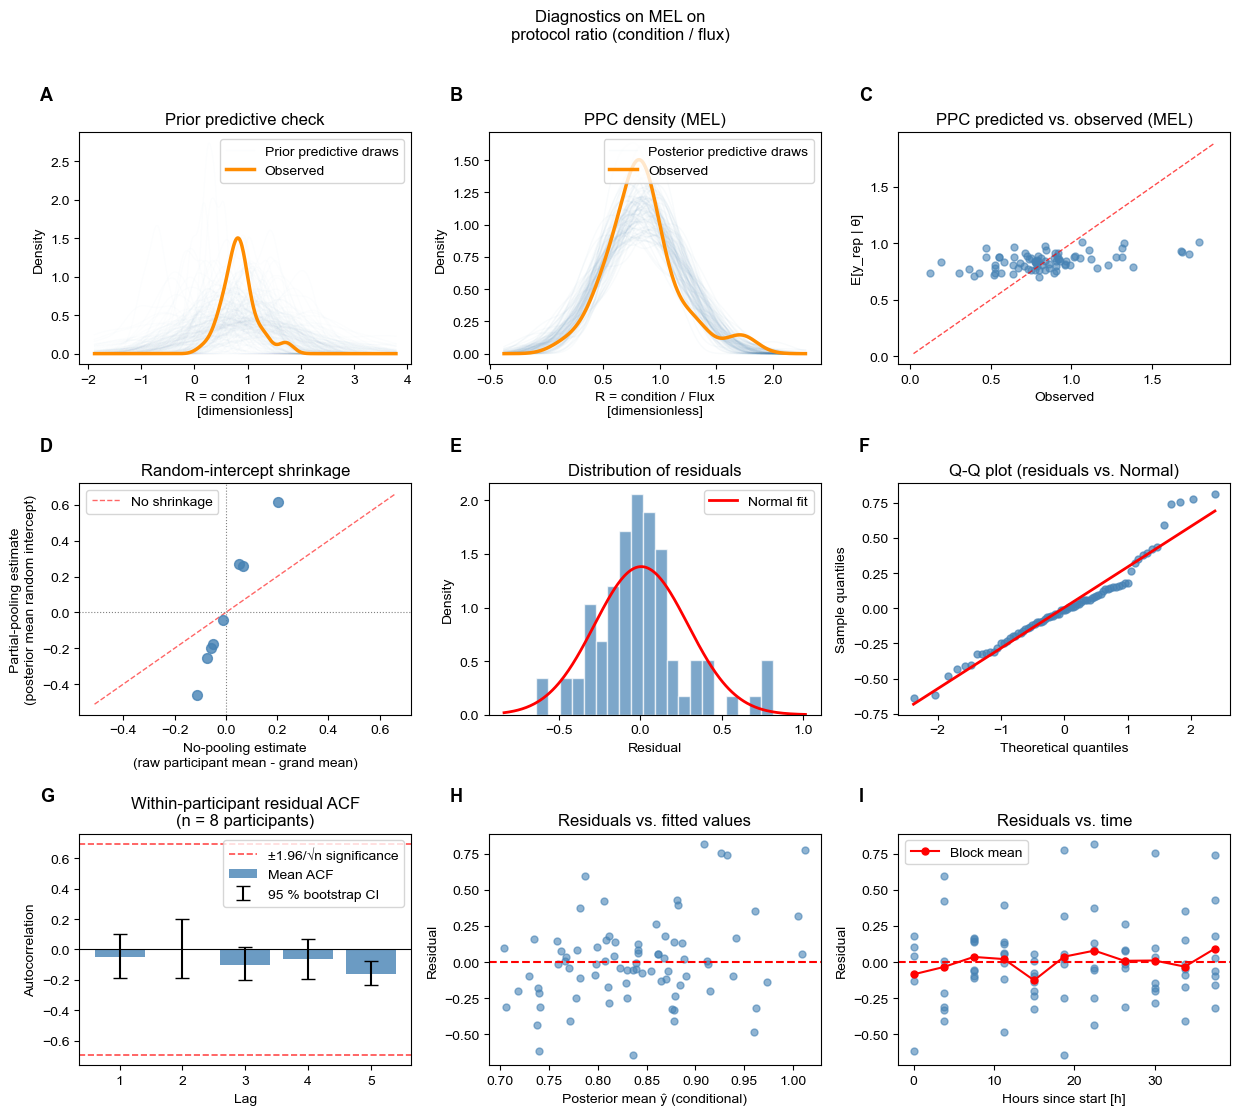

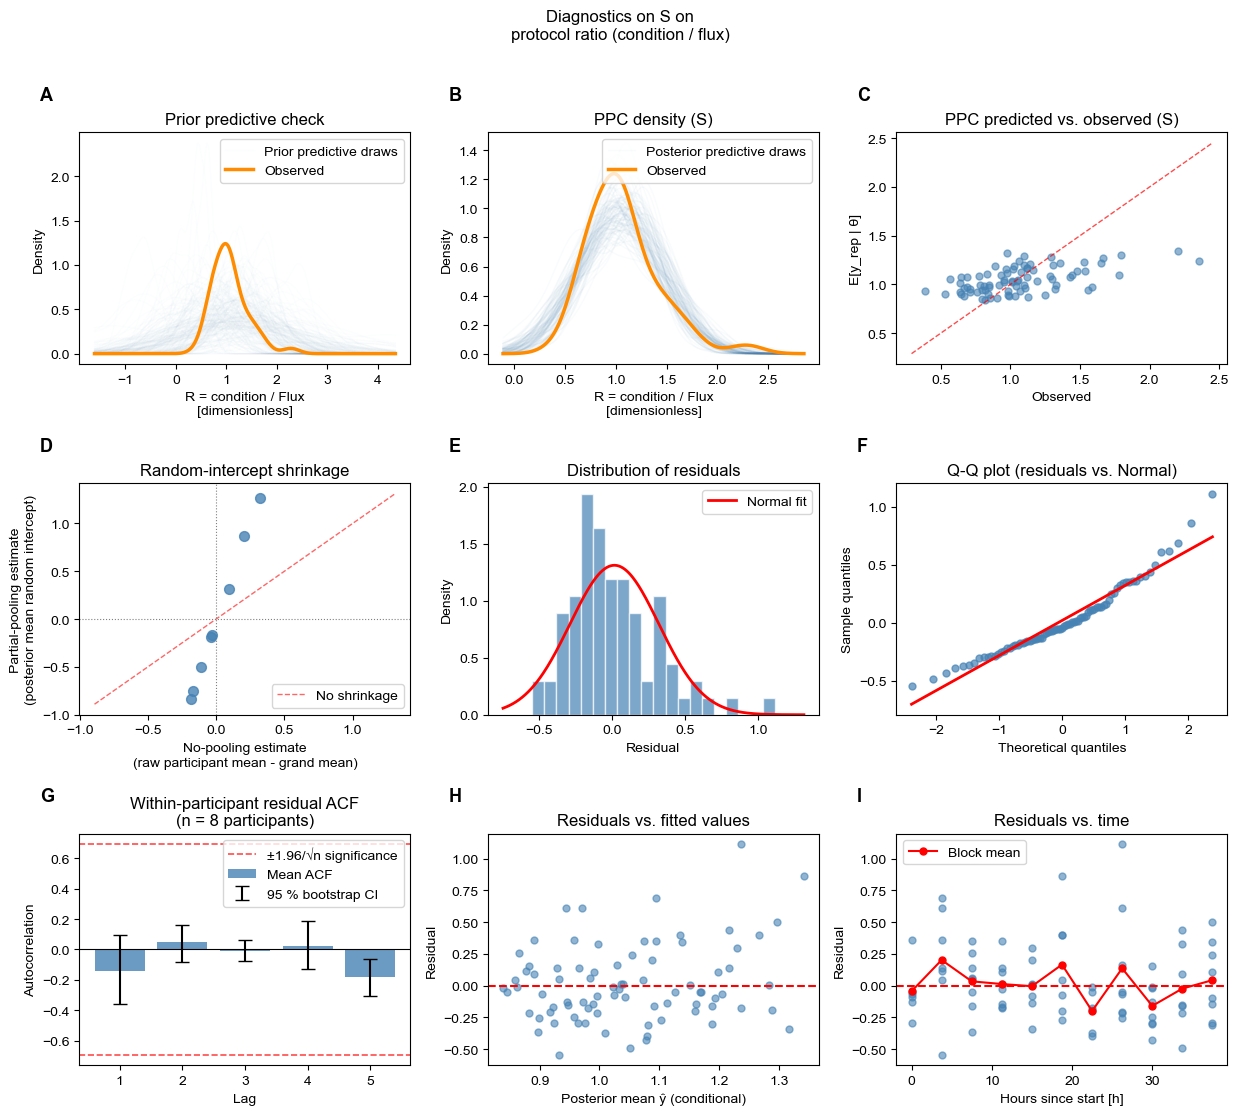

In [16]:
protocol_diag_results["plr_ratio"] = diagnose_protocol_plr(outcome_col="plr_ratio")

In [17]:
diag = pd.read_csv(DIAG / 'plr_ratio' / 'diagnostics_summary.csv')
display(diag[['condition','log_bf10','bf_SD_over_difference','pB_mean','pB_sd',
              'shapiro_W','shapiro_p','max_rhat_m0','max_rhat_m1']].round(4))


,condition,log_bf10,bf_SD_over_difference,pB_mean,pB_sd,shapiro_W,shapiro_p,max_rhat_m0,max_rhat_m1
0,l-m,-0.321,0.1516,0.3792,0.6390,0.9652,0.0392,1.0021,1.0008
1,lms,-2.090,0.0044,0.4577,0.6794,0.9003,0.0000,1.0002,1.0003
2,mel,-1.383,0.0247,0.4627,0.6671,0.9531,0.0052,1.0003,1.0007
3,s,-1.581,0.0259,0.3724,0.6534,0.9459,0.0019,1.0019,1.0003


#### Conclusion: the sampling is fine, the normality assumption is not

- **Sampling.** R-hat <= 1.002 everywhere, and Bayesian p-values for the mean are
  0.37-0.46. R-hat here compares independently started SMC runs; it detects
  disagreement between runs, not mixing within one chain.
- **Residuals.** Normality is rejected in every condition (Shapiro p: lms < 0.0001,
  s 0.002, mel 0.005, l-m 0.039). This is the skew the ratio inherits from its
  denominator, and the reason for the log-ratio check below.
- **Precision of the Bayes factor.** Adequate everywhere except L-M, where
  SD/|difference| = 0.15 because the Bayes factor is so close to zero. The log ratio
  brings this down to 0.056, so for L-M the log-ratio value is the more precise one.


### Step 5c -- Visualise circadian fits: plr_ratio


#### Figure 4 -- evidence across the three outcomes

`results/figures/circadian_cosinor/plr_ratio/fig_plr_ratio_bf_comparison.png`

Marker shape shows the outcome, colour the condition; the shaded band marks evidence too
weak to favour either model. Putting the three outcomes on one axis is possible because
a log Bayes factor has no units; the outcomes themselves are in different units and are
never plotted on a shared scale.


Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/plr_ratio/fig_plr_ratio_bf_comparison.png


PosixPath('/Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/plr_ratio/fig_plr_ratio_bf_comparison.png')

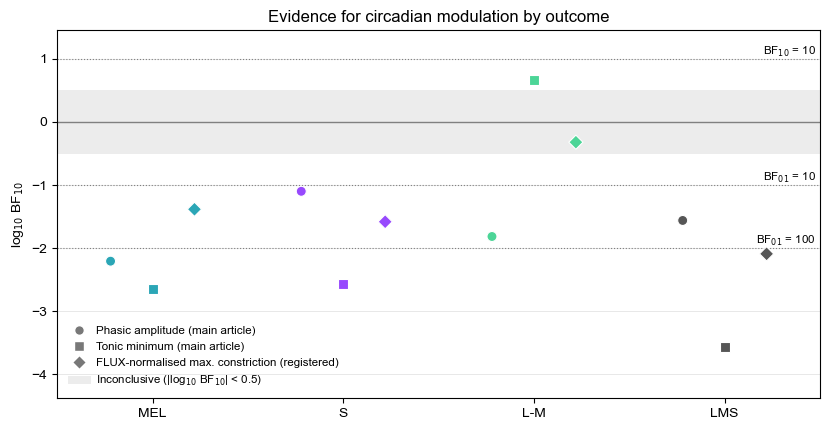

In [18]:
from civibeplr.si_visualise_protocol_plr import (
    DEFAULT_CIRCADIAN_FIG_DIR,
    collect_bf_table,
    plot_bf_comparison,
)

plot_bf_comparison(collect_bf_table('plr_ratio'), DEFAULT_CIRCADIAN_FIG_DIR / 'plr_ratio')

#### Figure 5 -- model fits against the observed data

The main pipeline's Step 5c all-conditions figure
(`visualise_circadian_parameter_cosinor.main` with `layout='combined'`).

`results/figures/circadian_cosinor/plr_ratio/fig_fitted_vs_empirical_all_conditions.png`

One panel per condition: the population-level posterior mean with its 95% interval, the
observed block means, and each participant's observed ratios as thin connected points.
The final panel compares the circadian amplitude and Bayes factor across conditions.


── All conditions ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/plr_ratio/fig_fitted_vs_empirical_all_conditions.png


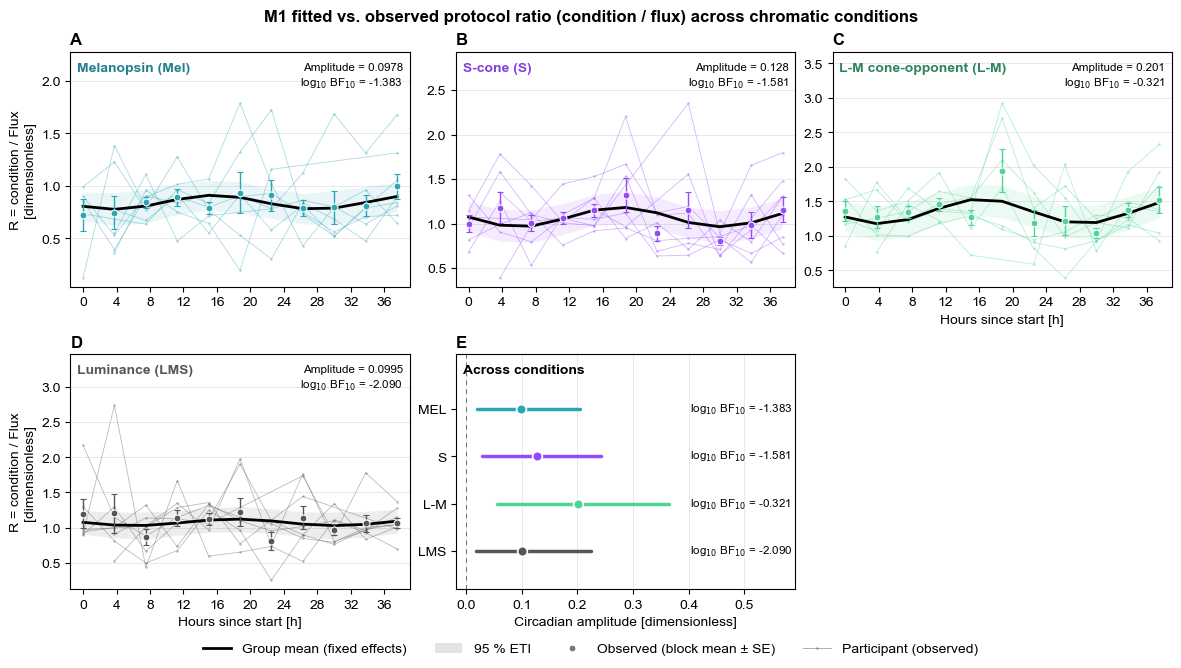

In [19]:
from civibeplr.visualise_circadian_parameter_cosinor import main as visualise_circadian

visualise_circadian(outcome_col='plr_ratio', layout='combined')

#### Does the choice of outcome change the manuscript's conclusion?


In [20]:
bf = collect_bf_table('plr_ratio')
display(bf.pivot_table(index='condition', columns='metric', values='log_bf10').round(2))

metric,amplitude,plr_ratio,tonic_min
condition,,,
flux,-3.36,NaN,-2.16
l-m,-1.81,-0.32,0.67
lms,-1.56,-2.09,-3.56
mel,-2.21,-1.38,-2.65
s,-1.10,-1.58,-2.57


#### Conclusion: no

The protocol outcome agrees with the manuscript's phasic amplitude: the constant-level
model is favoured in every condition. The deviation changed what was measured, not the
conclusion.

One difference should be noted. The tonic minimum is the only outcome that favours a
circadian effect anywhere, in L-M (log10 BF10 = +0.67). The protocol outcome does not
reproduce it (-0.32, inconclusive), although it mostly reflects the sustained
constriction (Step 3.2). Step 6b returns to what this means for the L-M tonic result.


## Outcome: log_plr_ratio

The logarithm of the ratio, specified as a sensitivity analysis before fitting. It exists
for every observation because all ratios are positive (Step 3.1). It checks the raw
result; it does not replace it.


### Step 4b -- Inspect outcome distribution: log_plr_ratio

The same check on the log scale, written to
`results/figures/circadian_cosinor/fig_parameter_distribution_log_plr_ratio.png`. The
same caveat applies: the pooled distribution is descriptive, and Step 5b is the check
that matters.


Loaded 315 paired ratios from paired_ratios_analysis.csv

Analysis dataframe: 315 rows  |  8 participants  |  4 conditions
\Parameter distribution check: 'log_plr_ratio'
Condition        N     Mean       SD     Skew     Kurt        W        p  Normal?
---------------------------------------------------------------------------------
l-m             74    0.252    0.337   -0.453    1.322   0.9804   0.3039  yes
lms             80    0.007    0.365   -0.487    2.242   0.9584   0.0108  NO
mel             80   -0.248    0.431   -1.313    4.042   0.9059   0.0000  NO
s               81    0.013    0.323    0.010    0.368   0.9916   0.8810  yes

  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/fig_parameter_distribution_log_plr_ratio.png


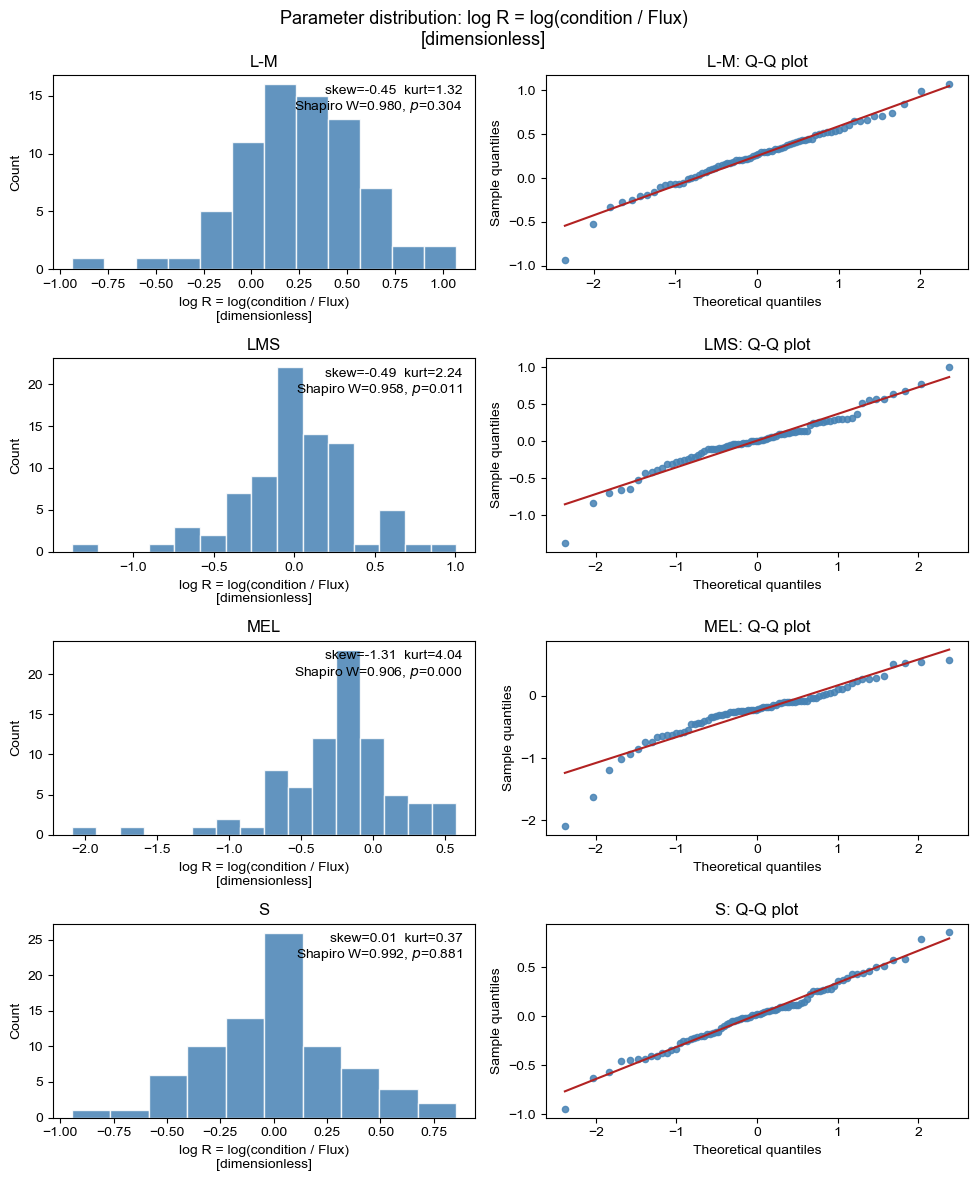

In [21]:
protocol_inspect_results["log_plr_ratio"] = inspect_protocol_plr(outcome_col="log_plr_ratio")

#### Conclusion: the log fixes two conditions, not four

- **S and L-M:** skew removed (S: skewness 0.01, p = 0.88; L-M: p = 0.30).
- **LMS:** still borderline (p = 0.011).
- **Mel:** over-corrected into a left tail (skewness -1.31, p < 0.0001), because its two
  smallest ratios (0.12 and 0.20) become large negative values on the log scale.

The Step 5b residuals show the same pattern. That is why the log ratio is used as a
check on the raw result rather than as a replacement.


### Step 5 -- Circadian models: log_plr_ratio

As for `plr_ratio`: sampling runs only with `FIT = True`.


In [22]:
df_protocol_log_plr_ratio, protocol_results["log_plr_ratio"] = analyse_protocol_plr(
    outcome_col="log_plr_ratio",
    force=FORCE,
    dry_run=not FIT,
    smc_draws=SMC_DRAWS,
    random_seed=SEED,
)

Loaded 315 paired ratios from paired_ratios_analysis.csv

Analysis dataframe: 315 rows  |  8 participants  |  4 conditions

── Outcome descriptives ──
Trial type  n_obs  n_participants  numerator_mean_mm  denominator_mean_mm  denominator_min_mm  ratio_mean  ratio_sd  ratio_median  ratio_min  ratio_max  ratio_skew  ratio_iqr
       l-m     74               7              1.259                1.000               0.363       0.252     0.337         0.271     -0.939      1.072      -0.462      0.381
       lms     80               8              1.022                0.995               0.363       0.007     0.365         0.008     -1.380      1.007      -0.496      0.365
       mel     80               8              0.811                1.005               0.363      -0.248     0.431        -0.217     -2.090      0.580      -1.338      0.366
         s     81               8              1.010                1.002               0.363       0.013     0.323         0.018     -0.945      0.8

### Step 5b -- Diagnose circadian models: log_plr_ratio

The same check and figures as for `plr_ratio`, on the log scale, written to
`results/figures/circadian_cosinor_diagnostics/log_plr_ratio/`.


Auto-detected conditions: ['l-m', 'lms', 'mel', 's']

── Condition: L-M ──────────────────
  Bayesian p-value: p_B(mean)=0.420  p_B(SD)=0.643
  Saved: posterior_params_l-m.csv
  r_hat  M0 max=1.0009  M1 max=1.0004
  Saved: fig_log_plr_ratio_diagnostics_l-m.png

── Condition: LMS ──────────────────
  Bayesian p-value: p_B(mean)=0.473  p_B(SD)=0.681
  Saved: posterior_params_lms.csv
  r_hat  M0 max=1.0003  M1 max=1.0002
  Saved: fig_log_plr_ratio_diagnostics_lms.png

── Condition: MEL ──────────────────
  Bayesian p-value: p_B(mean)=0.514  p_B(SD)=0.661
  Saved: posterior_params_mel.csv
  r_hat  M0 max=1.0001  M1 max=1.0004
  Saved: fig_log_plr_ratio_diagnostics_mel.png

── Condition: S ──────────────────
  Bayesian p-value: p_B(mean)=0.371  p_B(SD)=0.652
  Saved: posterior_params_s.csv
  r_hat  M0 max=1.0020  M1 max=1.0004
  Saved: fig_log_plr_ratio_diagnostics_s.png
  Saved: logz_variance_all_conditions.png
Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/tables/

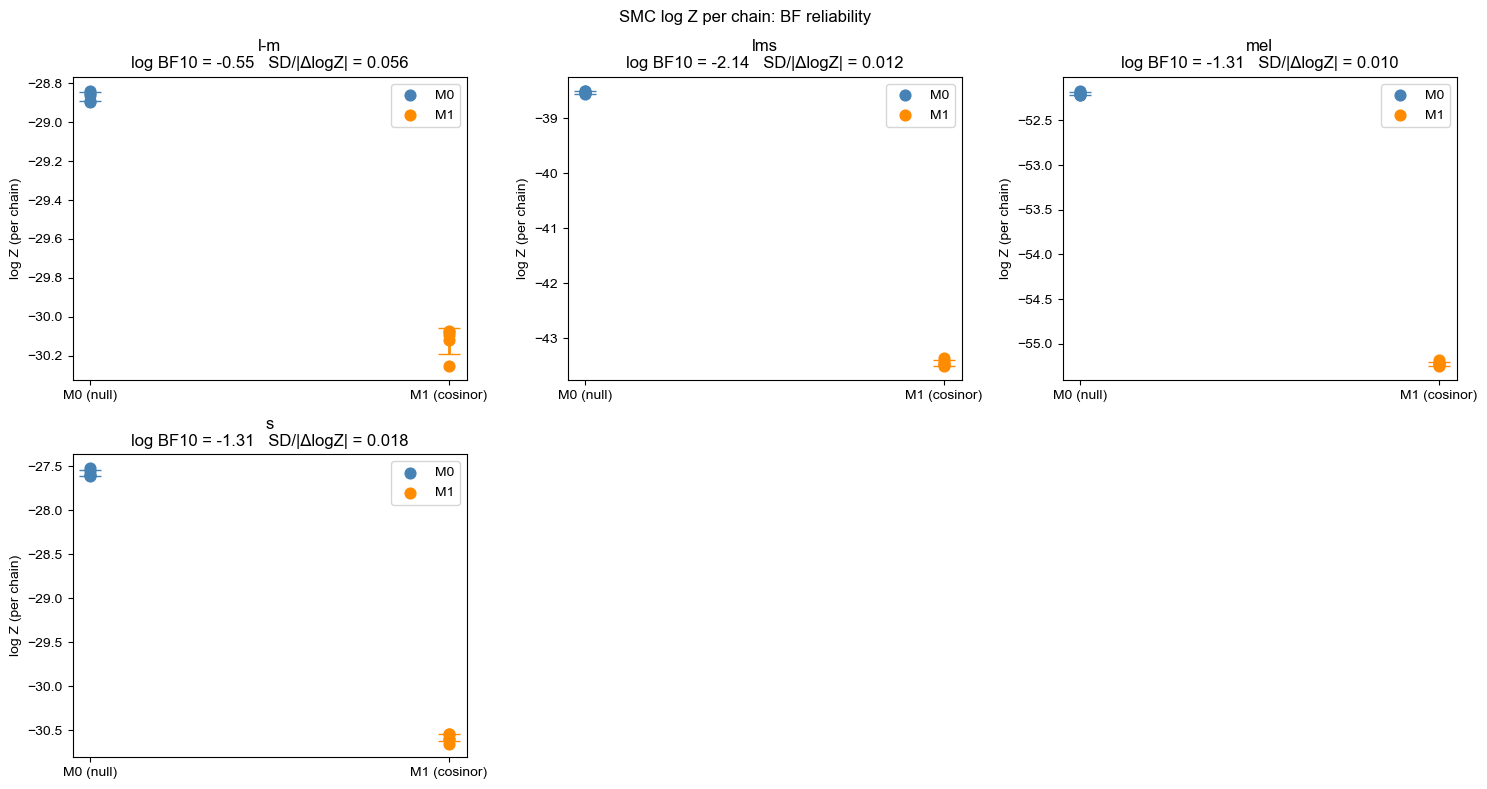

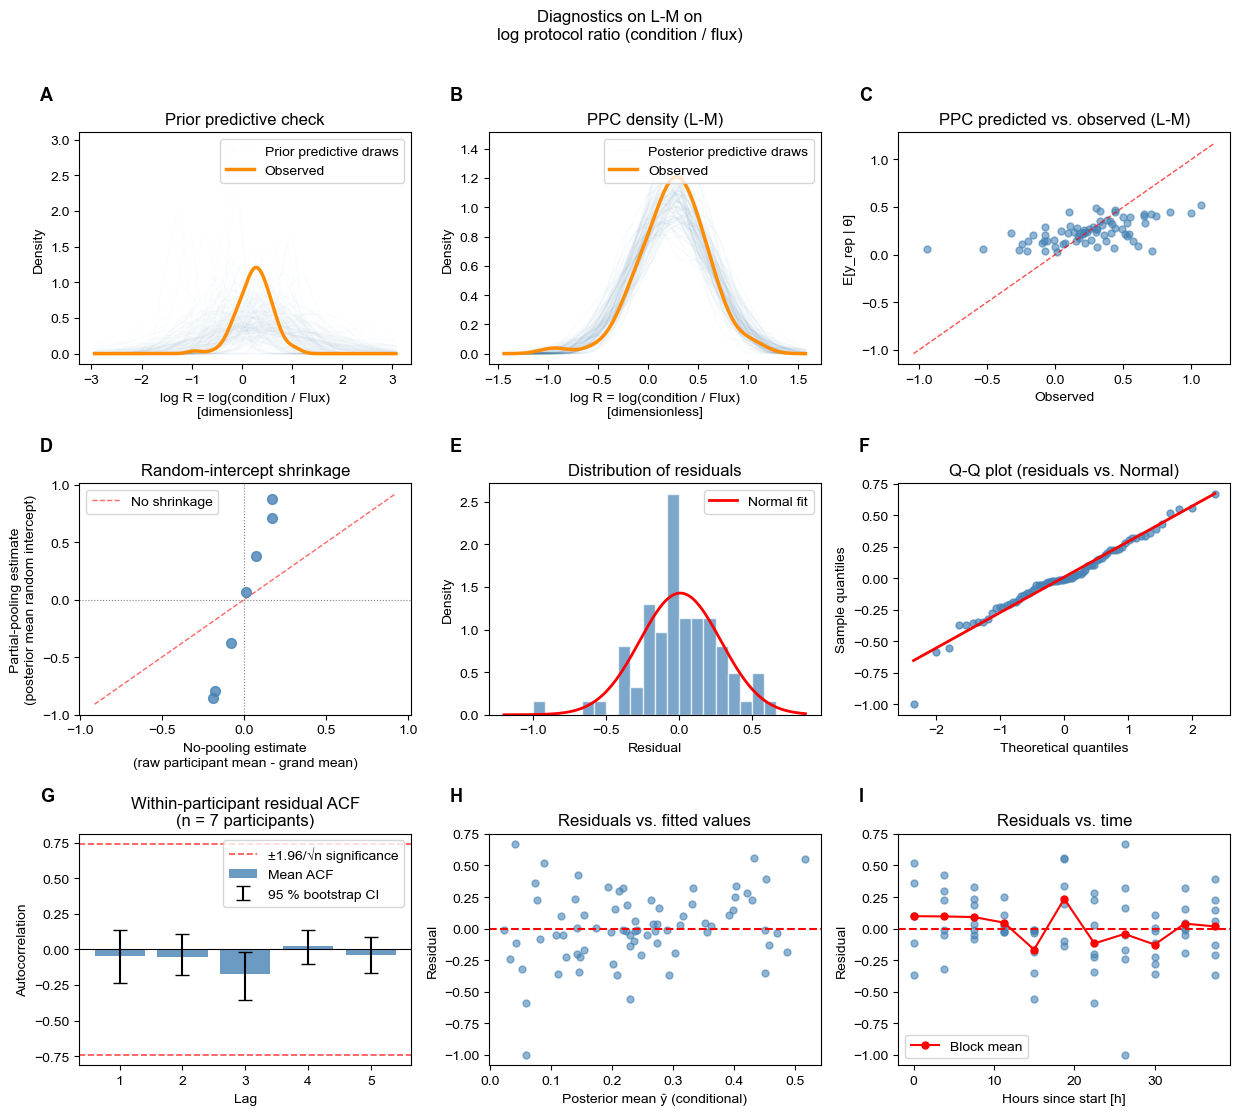

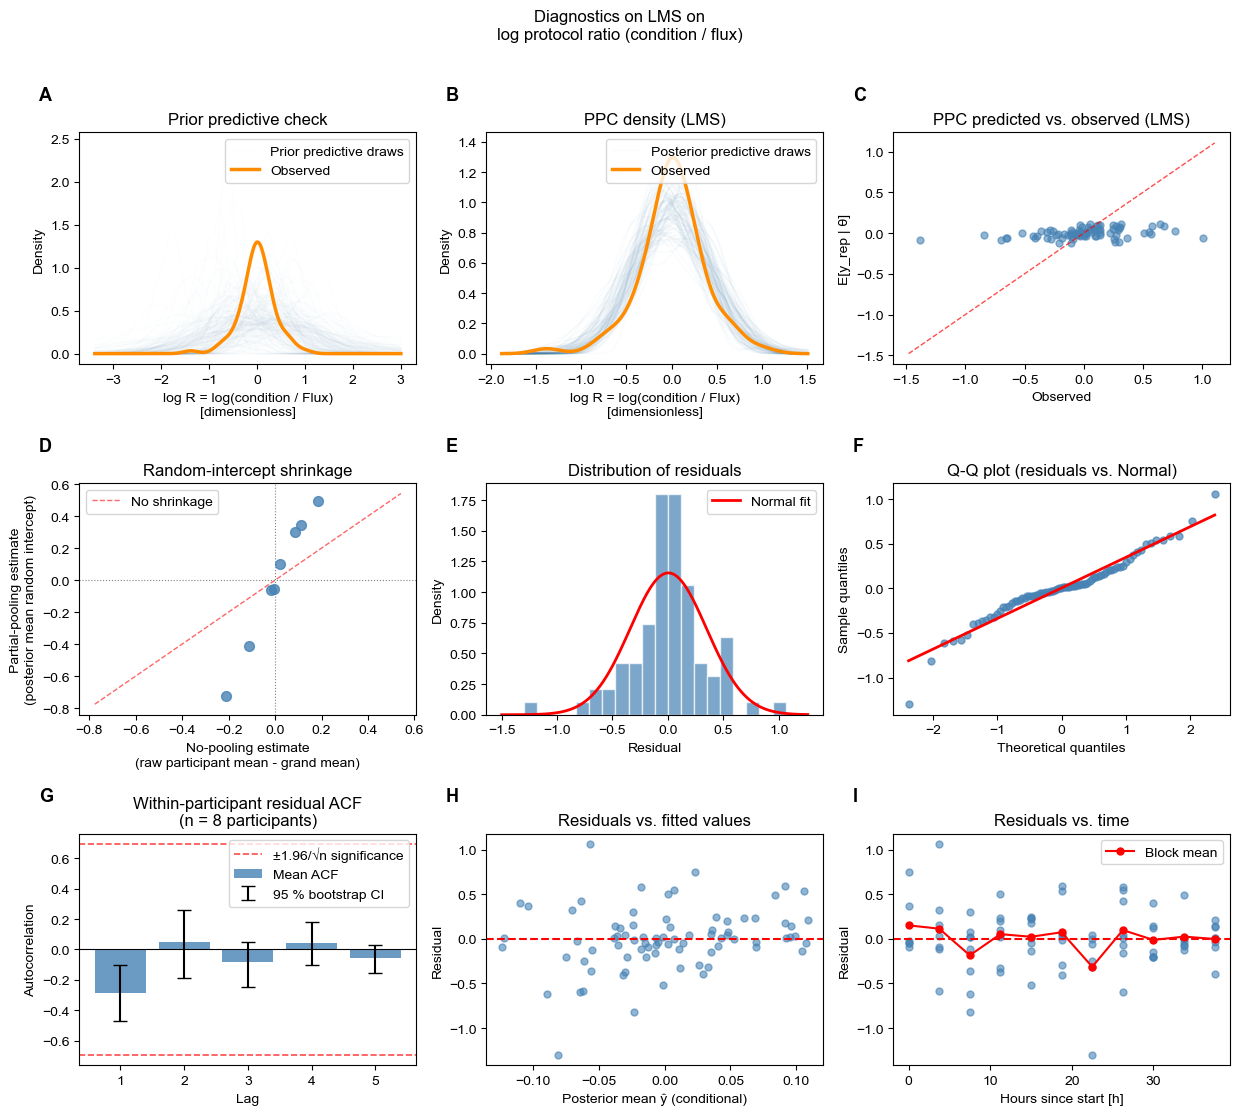

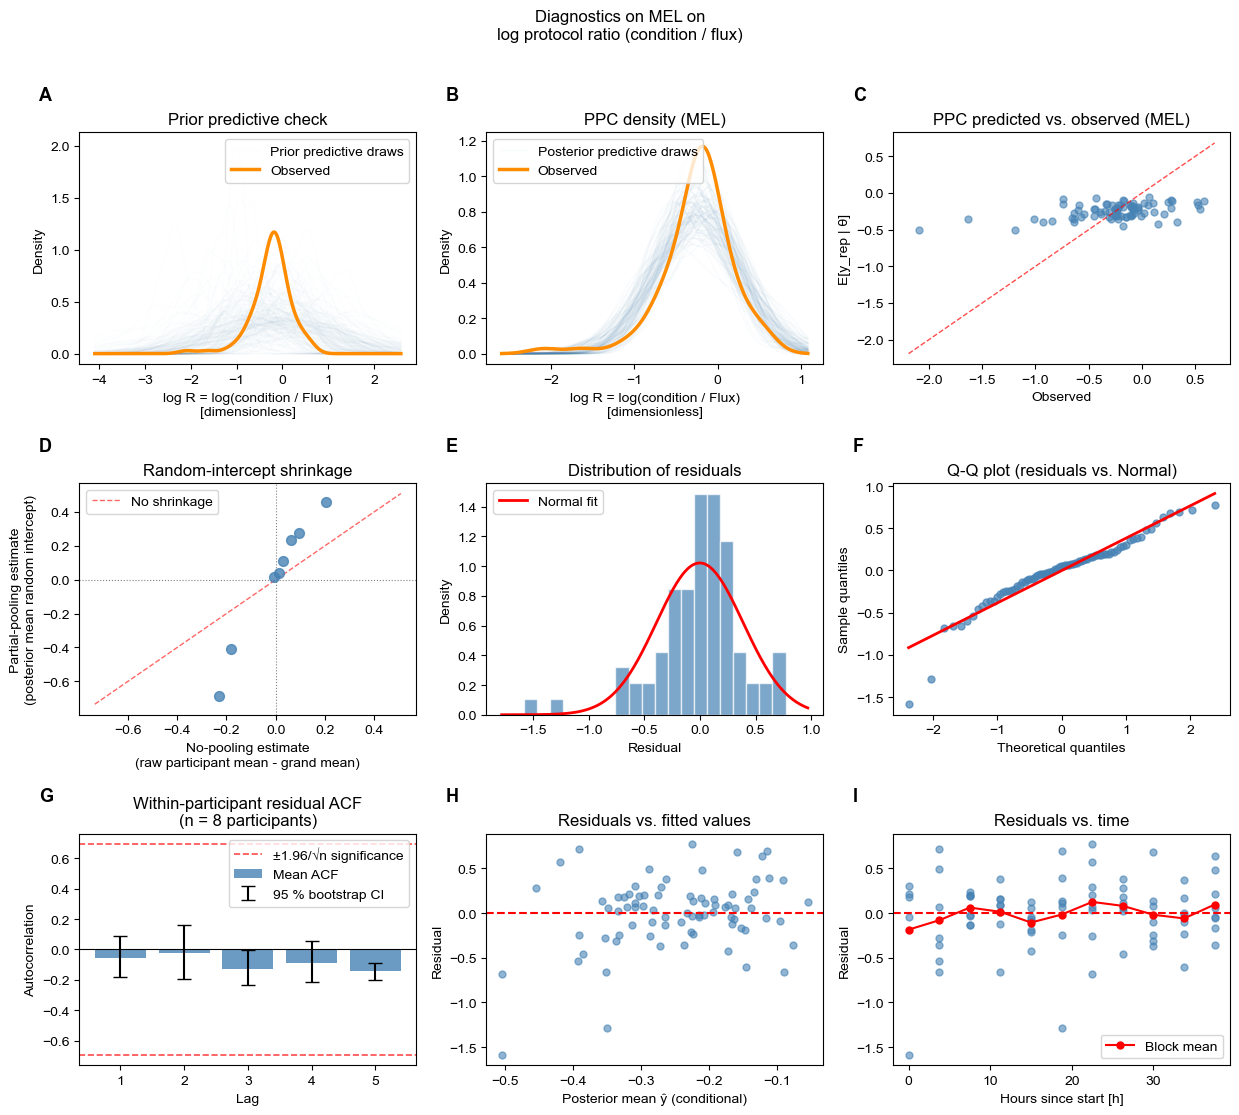

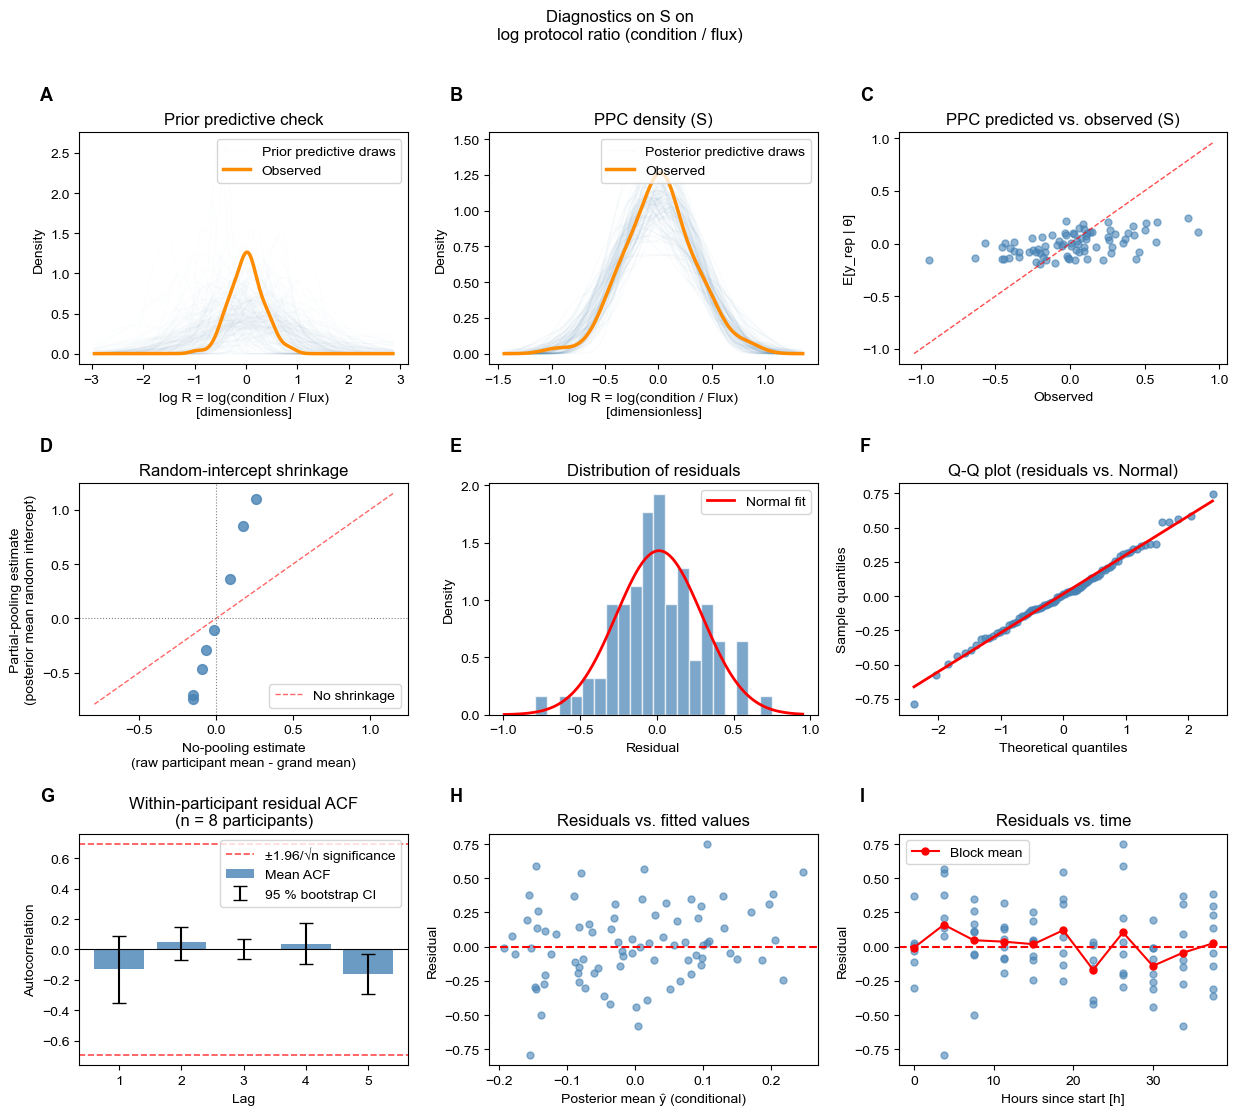

In [23]:
protocol_diag_results["log_plr_ratio"] = diagnose_protocol_plr(outcome_col="log_plr_ratio")

### Step 5c -- Visualise circadian fits: log_plr_ratio

The same figure as Figure 5, on the log scale. Written to
`results/figures/circadian_cosinor/log_plr_ratio/fig_fitted_vs_empirical_all_conditions.png`.
Figure 4 is not repeated, because it already compares the outcomes.


── All conditions ──────────────────
  Saved: /Users/hheinrichs/Documents/projects/civibe_pupillometry/results/figures/circadian_cosinor/log_plr_ratio/fig_fitted_vs_empirical_all_conditions.png


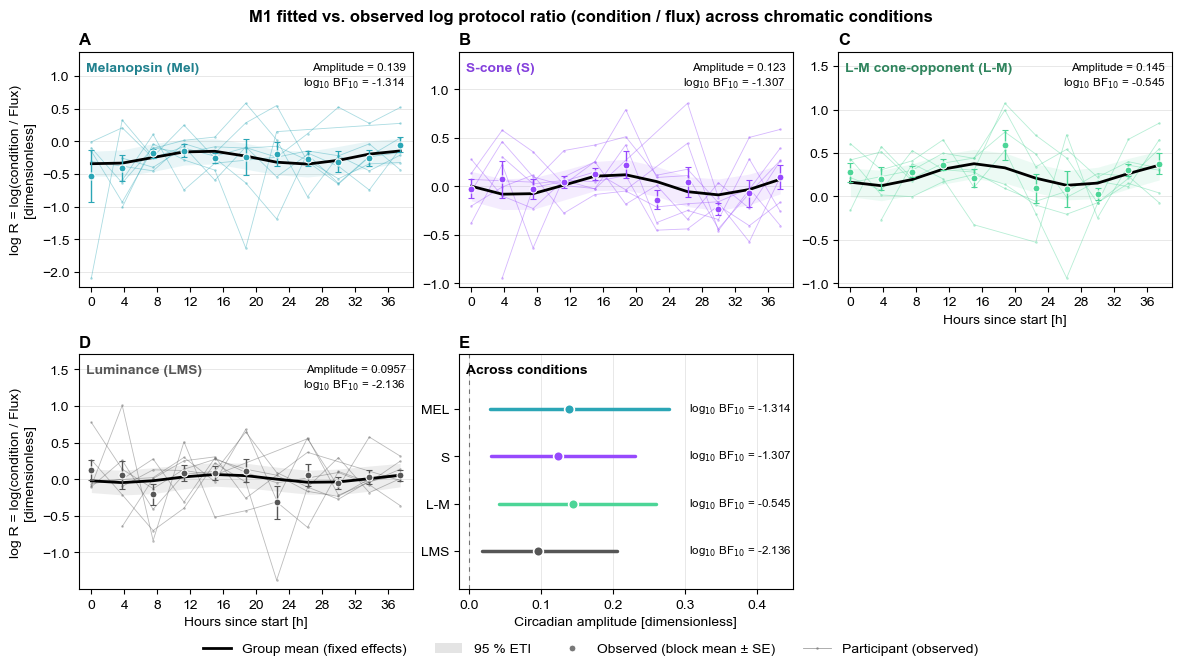

In [24]:
visualise_circadian(outcome_col='log_plr_ratio', layout='combined')

#### Raw against log ratio


In [25]:
raw = pd.read_csv(TABLES / 'plr_ratio'     / 'circadian_pupil_all_conditions.csv')
log = pd.read_csv(TABLES / 'log_plr_ratio' / 'circadian_pupil_all_conditions.csv')
cmp = raw[['condition','n_obs','log_bf10']].merge(
    log[['condition','log_bf10']], on='condition', suffixes=('_raw','_log'))
dg  = pd.read_csv(DIAG / 'log_plr_ratio' / 'diagnostics_summary.csv')
cmp = cmp.merge(dg[['condition','shapiro_p']].rename(columns={'shapiro_p':'shapiro_p_log'}),
                on='condition')
display(cmp.round(4))


,condition,n_obs,log_bf10_raw,log_bf10_log,shapiro_p_log
0,l-m,74,-0.3211,-0.5451,0.1295
1,lms,80,-2.0897,-2.1365,0.0054
2,mel,80,-1.3834,-1.3144,0.0002
3,s,81,-1.5808,-1.3072,0.9810


#### Conclusion: the result does not depend on the normality assumption

No condition changes its reading under the log transform: every Bayes factor stays on
the same side and in the same range. The transform itself is not a cure: it repairs
normality for S and L-M, leaves LMS borderline and makes Mel worse. What matters is
that the Bayes factors agree either way.


---
## Step 6 -- Sensitivity analyses (no main counterpart)

These two checks run independently on `plr_ratio` and were specified before fitting.
They change different parts of the analysis:

| Check | Changes | Holds fixed |
|---|---|---|
| 6a: Period-search range | Saliva period search: 22-28 h to 20-28 h | All participants; two-harmonic saliva model |
| 6b: Participant influence (LOPO) | One participant omitted per refit | Period estimates from the usual 22-28 h search |

LOPO does not use the widened-period fit. Each section has its own execution cell,
saved results and interpretation. With `FIT = False`, the refits are skipped and the
saved tables are displayed.


### Step 6a -- Sensitivity to the period-search range

**Question.** Does using the protocol's 20-28 h range change the estimated periods
or evidence for circadian modulation?

**Method.** Refit the saliva cosinor over 20-28 h in a separate folder, then refit
the circadian models for all four conditions with all participants retained.
Only the range is restored: the saliva model still has two harmonics, rather than
the protocol's single harmonic (see Step 4).

**In:** paired block ratios and saliva data.
**Out:** `results/tables/plr_ratio/sensitivity/registered_period.csv`,
`registered_period_taus.csv`, and the saliva refit under
`data/derivatives/plr_ratio/registered_period/`.


In [26]:
from civibeplr.si_sensitivity_protocol_plr import main as si_sensitivity_protocol_plr

if FIT:
    period_sensitivity_results = si_sensitivity_protocol_plr(
        analyses=["registered-period"], outcome_col="plr_ratio",
        smc_draws=SMC_DRAWS, seed=SEED,
    )
else:
    print("Period-range refit skipped (FIT = False); displaying saved results below.")


Period-range refit skipped (FIT = False); displaying saved results below.


In [27]:
display(Markdown('**Registered 20-28 h period range**'))
display(pd.read_csv(SENS / 'registered_period.csv').round(3))
taus = pd.read_csv(SENS / 'registered_period_taus.csv')
display(taus.round(3))
print('All taus identical between ranges:', bool((taus.delta_hours.abs() < 1e-9).all()))


**Registered 20-28 h period range**

,analysis,condition,n_obs,n_participants,log_bf10
0,registered_period_20_28,l-m,74,7,-0.321
1,registered_period_20_28,lms,80,8,-2.090
2,registered_period_20_28,mel,80,8,-1.383
3,registered_period_20_28,s,81,8,-1.581


,participant_id,tau_primary_22_28,tau_registered_20_28,delta_hours
0,200,24.250,24.250,-0.0
1,201,24.250,24.250,-0.0
2,202,25.167,25.167,-0.0
3,204,23.533,23.533,-0.0
4,206,23.650,23.650,-0.0
5,211,24.133,24.133,-0.0
6,212,24.033,24.033,-0.0
7,213,23.067,23.067,-0.0


All taus identical between ranges: True


#### Interpretation: the wider period range selects the same periods

Every participant's best period already lies between 23.07
and 25.17 h, well inside 22-28 h. The wider protocol range selects the same period for
everyone, and the Bayes factors are identical to three decimal places. The narrowed
range is a documented deviation with no consequence for these data.



### Step 6b -- Sensitivity to individual participants (LOPO)

**Question.** Does the evidence for circadian modulation depend on which
participants are included?

**Method.** Leave one whole participant out per refit of the raw-ratio model.
Use the period estimates from the usual 22-28 h search, independently of Step 6a.
Only L-M is checked: its evidence sits near the decision boundary, so it is
the condition where one participant could change the conclusion.

**In:** paired block ratios and the usual 22-28 h saliva periods.
**Out:** `results/tables/plr_ratio/sensitivity/lopo_lm_plr_ratio.csv` and
`lopo_lm_summary_plr_ratio.csv`.


In [28]:
from civibeplr.si_sensitivity_protocol_plr import main as si_sensitivity_protocol_plr

if FIT:
    lopo_sensitivity_results = si_sensitivity_protocol_plr(
        analyses=["lopo"], outcome_col="plr_ratio",
        smc_draws=SMC_DRAWS, seed=SEED,
    )
else:
    print("LOPO refits skipped (FIT = False); displaying saved results below.")


LOPO refits skipped (FIT = False); displaying saved results below.


In [29]:
display(Markdown('**Leave-one-participant-out -- L-M only**'))
display(pd.read_csv(SENS / 'lopo_lm_summary_plr_ratio.csv').round(3))
lm = pd.read_csv(SENS / 'lopo_lm_plr_ratio.csv')
display(lm[['held_out','n_obs','log_bf10','delta_vs_full']].round(3))


**Leave-one-participant-out -- L-M only**

,condition,log_bf10_full,log_bf10_min,log_bf10_max,max_abs_delta,most_influential,crosses_zero
0,l-m,-0.321,-0.884,0.384,0.705,204,True


,held_out,n_obs,log_bf10,delta_vs_full
0,none,74,-0.321,0.000
1,200,63,-0.057,0.264
2,201,63,-0.309,0.012
3,202,63,-0.884,-0.563
4,204,65,0.384,0.705
5,206,64,-0.431,-0.110
6,211,63,-0.412,-0.091
7,212,63,-0.721,-0.400


#### Interpretation: L-M model preference depends on participant inclusion

Its Bayes factor is close to
zero (log10 BF10 = -0.32), and leaving out one participant moves it anywhere from -0.88
to +0.38, so which model is favoured depends on who is included. Participant 204 alone
shifts it by +0.71. The other three conditions were stable (largest shift 0.54, on a
Bayes factor of -2.09).

This is the same condition in which the tonic minimum gives the only positive Bayes
factor (+0.67). Two separate observations therefore argue against relying on that
result: the protocol outcome does not reproduce it, and the protocol outcome's own L-M
result depends on single participants.


---
## Summary

**Result.** The protocol outcome favours the constant-level model in all four
conditions, as the manuscript's phasic amplitude does. The conclusion does not depend on
which of the three pupil outcomes is analysed.

**Why the manuscript deviated.** Maximum constriction mostly reflects the sustained
constriction, not how the pupil follows the 0.4 Hz oscillation: L-M ranks first on it
but fourth on the phasic amplitude (Step 3.2, Figure 1).

**L-M tonic minimum.** The one positive Bayes factor in the manuscript is not supported
here (Step 6b).

**Limitations.**

- R is relative to flux, so a change can come from the condition, from flux, or both,
  and changes shared with flux cancel.
- The four ratios share the same flux observations, so they are not four independent
  tests.
- The per-trial maximum carries a condition-specific bias of 5-18% (Step 3.3).
- Residual normality is rejected for the raw ratio; the log ratio gives the same
  answer.
- 7-8 participants per condition; L-M depends on single participants.
- What could not be restored from the protocol is listed at the top ("What this
  supplementary analysis cannot deliver").

---

## Reproducing this notebook

```bash
# everything, with fitting (main pipeline Step 4 must have run first)
python si_pipeline.py --fit --seed 1072

# or step by step
python si_pipeline.py --steps 3 3b
python si_pipeline.py --steps 4b 5 5b 5c --fit --outcomes plr_ratio
python si_pipeline.py --steps 4b 5 5b 5c --fit --outcomes log_plr_ratio
python si_pipeline.py --steps 6 --fit

# or run either sensitivity check independently
python -m civibeplr.si_sensitivity_protocol_plr --analyses registered-period
python -m civibeplr.si_sensitivity_protocol_plr --analyses lopo

# tests
python -m pytest tests/ -q
```

`pipeline.py` does not include these steps, so running the main pipeline never touches
them.
